# 01. Construcción del dataset analítico: estancia restante en UCI a las 12 horas

Este notebook construye un conjunto analítico a nivel de **estancia en UCI (`stay_id`)** para estimar la **duración restante de la estancia** a partir de la información disponible desde el ingreso a UCI hasta antes de cumplir 12 horas.

- **Unidad de análisis:** una estancia en UCI (`stay_id`).
- **Punto de predicción:** 12 horas después de `intime`.
- **Cohorte elegible:** estancias con `los >= 0.5` días; por diseño, el problema se refiere a pacientes que continúan en UCI a las 12 horas.
- **Ventana de información:** `0 <= horas_desde_ingreso < 12` en signos vitales y laboratorios.
- **Objetivo:** `los_restante_dias = los - 0.5`.


### Objetivo
Construir el dataset analítico para la predicción de la estancia hospitalaria restante en UCI a partir de información disponible durante las primeras 12 horas de estancia.

### Fuente de datos
MIMIC-IV 3.1

### Entrada
Tablas clínicas provenientes de los módulos `hosp` e `icu` de MIMIC-IV.

###  Salida
`data/interim/mimic_uci_12h_dataset_analitico.csv.gz`

### Siguiente etapa
El dataset generado será utilizado en:

`02_eda_dataset_analitico.ipynb`


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.stats import spearmanr
import seaborn as sns
from pathlib import Path

import sys
from pathlib import Path

def encontrar_raiz_proyecto():
    actual = Path.cwd().resolve()
    for candidato in [actual, *actual.parents]:
        if (candidato / "src" / "config.py").exists():
            return candidato
    raise FileNotFoundError(
        "No se encontró la raíz del proyecto. "
        "Ejecuta este notebook dentro del repositorio estancia-hospitalaria-uci."
    )

PROJECT_ROOT = encontrar_raiz_proyecto()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import HOSP_DIR, ICU_DIR, INTERIM_DIR

PUNTO_PREDICCION_H = 12
PUNTO_PREDICCION_DIAS = PUNTO_PREDICCION_H / 24

print("HOSP_DIR:", HOSP_DIR)
print("ICU_DIR:", ICU_DIR)
print("INTERIM_DIR:", INTERIM_DIR)


HOSP_DIR: C:\Users\grise\Downloads\mimic-iv-3.1\mimic-iv-3.1\hosp
ICU_DIR: C:\Users\grise\Downloads\mimic-iv-3.1\mimic-iv-3.1\icu
INTERIM_DIR: C:\Users\grise\Downloads\estancia-hospitalaria-uci\data\interim


## 1. Carga y validación de fuentes


In [2]:
patients = pd.read_csv(HOSP_DIR / "patients.csv.gz")
admissions = pd.read_csv(HOSP_DIR / "admissions.csv.gz")
icustays = pd.read_csv(ICU_DIR / "icustays.csv.gz")

icustays["intime"] = pd.to_datetime(icustays["intime"])
icustays["outtime"] = pd.to_datetime(icustays["outtime"])
admissions["admittime"] = pd.to_datetime(admissions["admittime"])

print("patients:", patients.shape)
print("admissions:", admissions.shape)
print("icustays:", icustays.shape)


patients: (364627, 6)
admissions: (546028, 16)
icustays: (94458, 8)


In [3]:
# Comprobar que stay_id es la unidad adecuada de análisis.
uci_por_paciente = icustays.groupby("subject_id")["stay_id"].nunique()
uci_por_hospitalizacion = icustays.groupby("hadm_id")["stay_id"].nunique()

print("Estancias UCI:", icustays["stay_id"].nunique())
print("Pacientes únicos en UCI:", icustays["subject_id"].nunique())
print("Pacientes con >1 estancia UCI:", (uci_por_paciente > 1).sum())
print("Hospitalizaciones con >1 estancia UCI:", (uci_por_hospitalizacion > 1).sum())


Estancias UCI: 94458
Pacientes únicos en UCI: 65366
Pacientes con >1 estancia UCI: 16242
Hospitalizaciones con >1 estancia UCI: 7695


In [4]:
# Validar LOS contra la diferencia entre outtime e intime.
icustays["los_calculado"] = (
    (icustays["outtime"] - icustays["intime"]).dt.total_seconds() / 86400
)
icustays["diferencia_los"] = (icustays["los"] - icustays["los_calculado"]).abs()

print("LOS faltantes:", icustays["los"].isna().sum())
print("LOS <= 0:", (icustays["los"] <= 0).sum())
print("Diferencia máxima LOS:", icustays["diferencia_los"].max())
print("Diferencia promedio LOS:", icustays["diferencia_los"].mean())


LOS faltantes: 14
LOS <= 0: 0
Diferencia máxima LOS: 1.4210854715202004e-14
Diferencia promedio LOS: 1.154972756396324e-16


## 2. Justificación del punto de predicción y definición de cohorte


In [5]:
# Comparación breve de cuántas estancias alcanzan distintos puntos de predicción.
comparacion_puntos = []
for horas in [6, 12, 24]:
    elegibles = icustays["los"] >= horas / 24
    comparacion_puntos.append({
        "punto_prediccion_h": horas,
        "estancias_elegibles": int(elegibles.sum()),
        "porcentaje_del_total": elegibles.mean() * 100
    })

display(pd.DataFrame(comparacion_puntos).round(2))


,punto_prediccion_h,estancias_elegibles,porcentaje_del_total
0,6,93224,98.69
1,12,90467,95.77
2,24,74829,79.22


In [6]:
# Cohorte definitiva: pacientes que continúan en UCI al cumplir 12 horas.
estancias_12h = icustays[
    icustays["los"] >= PUNTO_PREDICCION_DIAS
].copy()

# Objetivo coherente con una predicción realizada a las 12 h.
estancias_12h["los_restante_dias"] = (
    estancias_12h["los"] - PUNTO_PREDICCION_DIAS
)

print("Estancias elegibles:", len(estancias_12h))
print("stay_id únicos:", estancias_12h["stay_id"].nunique())
print("Mínimo LOS restante:", estancias_12h["los_restante_dias"].min())

assert estancias_12h["stay_id"].is_unique
assert (estancias_12h["los_restante_dias"] >= 0).all()


Estancias elegibles: 90467
stay_id únicos: 90467
Mínimo LOS restante: 0.0


**Interpretación de la cohorte.** A partir de este punto el análisis no representa a todas las admisiones a UCI, sino a las estancias que siguen activas a las 12 horas. Por ello, el objetivo es estimar cuánto tiempo adicional permanecerá el paciente en UCI desde ese momento.


## 3. Variables basales y contextuales


In [7]:
base_candidatos = (
    estancias_12h
    .merge(patients, on="subject_id", how="left")
    .merge(admissions, on=["subject_id", "hadm_id"], how="left")
)

base_candidatos["edad_ingreso"] = (
    base_candidatos["anchor_age"]
    + base_candidatos["admittime"].dt.year
    - base_candidatos["anchor_year"]
)

variables_basales = [
    "stay_id", "edad_ingreso", "gender",
    "admission_type", "admission_location"
]

print("Filas base:", len(base_candidatos))
print("stay_id únicos:", base_candidatos["stay_id"].nunique())
display(base_candidatos[variables_basales].head())


Filas base: 90467
stay_id únicos: 90467


,stay_id,edad_ingreso,gender,admission_type,admission_location
0,37081114,86,F,EW EMER.,EMERGENCY ROOM
1,37067082,55,F,EW EMER.,EMERGENCY ROOM
2,34592300,55,F,DIRECT EMER.,PHYSICIAN REFERRAL
3,31205490,46,F,EW EMER.,PACU
4,39698942,76,M,URGENT,TRANSFER FROM HOSPITAL


## 4. Signos vitales en la ventana 0–<12 h


In [8]:
# chartevents es una de las tablas más grandes de MIMIC-IV.
# Se procesa por chunks para no cargarla completa en RAM.

d_items = pd.read_csv(ICU_DIR / "d_items.csv.gz")

signos_vitales = {
    220045: "fc",
    220210: "fr",
    220277: "spo2",
    223761: "temperatura",
    220179: "pas",
    220180: "pad",
    220181: "pam"
}

ids_elegibles_12h = set(estancias_12h["stay_id"])
intime_elegibles = estancias_12h[["stay_id", "intime"]].copy()

columnas_chart = ["stay_id", "itemid", "charttime", "valuenum"]
chunks_signos = []

for chunk in pd.read_csv(
    ICU_DIR / "chartevents.csv.gz",
    usecols=columnas_chart,
    chunksize=1_000_000
):
    # Reducir el chunk antes de cualquier merge.
    chunk = chunk[
        chunk["stay_id"].isin(ids_elegibles_12h)
        & chunk["itemid"].isin(signos_vitales.keys())
        & chunk["valuenum"].notna()
    ].copy()

    if chunk.empty:
        continue

    chunk["charttime"] = pd.to_datetime(chunk["charttime"])
    chunk = chunk.merge(intime_elegibles, on="stay_id", how="inner")
    chunk["horas_desde_ingreso"] = (
        (chunk["charttime"] - chunk["intime"]).dt.total_seconds() / 3600
    )

    chunk = chunk[
        (chunk["horas_desde_ingreso"] >= 0)
        & (chunk["horas_desde_ingreso"] < PUNTO_PREDICCION_H)
    ].copy()

    if not chunk.empty:
        chunks_signos.append(chunk)

if chunks_signos:
    signos_12h = pd.concat(chunks_signos, ignore_index=True)
else:
    signos_12h = pd.DataFrame(
        columns=["stay_id", "itemid", "charttime", "valuenum", "intime", "horas_desde_ingreso"]
    )

# Añadir metadatos solo después de haber reducido chartevents.
signos_12h = signos_12h.merge(
    d_items[["itemid", "label", "abbreviation", "category", "unitname", "param_type"]],
    on="itemid",
    how="left"
)

print("Registros de signos en 0–<12 h:", len(signos_12h))
print("Estancias con al menos un signo:", signos_12h["stay_id"].nunique())


Registros de signos en 0–<12 h: 6968121
Estancias con al menos un signo: 90361


In [9]:
# Cobertura de los signos dentro de la cohorte elegible.
cobertura_signos = (
    signos_12h.groupby(["itemid", "label"])["stay_id"]
    .nunique().reset_index(name="estancias_con_variable")
)
cobertura_signos["cobertura_pct"] = (
    cobertura_signos["estancias_con_variable"] / len(estancias_12h) * 100
)
display(cobertura_signos.sort_values("cobertura_pct", ascending=False).round(2))


,itemid,label,estancias_con_variable,cobertura_pct
0,220045,Heart Rate,90356,99.88
5,220277,O2 saturation pulseoxymetry,90290,99.80
4,220210,Respiratory Rate,90078,99.57
6,223761,Temperature Fahrenheit,83080,91.83
1,220179,Non Invasive Blood Pressure systolic,75185,83.11
3,220181,Non Invasive Blood Pressure mean,75184,83.11
2,220180,Non Invasive Blood Pressure diastolic,75174,83.10


In [10]:
# Rangos usados únicamente como banderas de revisión, NO como criterio automático de eliminación.
rangos_revision = {
    220045: (30, 200),
    220179: (50, 250),
    220180: (20, 150),
    220181: (30, 180),
    220210: (5, 60),
    220277: (70, 100),
    223761: (93, 107)
}

revision = []
for itemid, (lim_inf, lim_sup) in rangos_revision.items():
    datos = signos_12h[signos_12h["itemid"] == itemid]
    fuera = datos[(datos["valuenum"] < lim_inf) | (datos["valuenum"] > lim_sup)]
    revision.append({
        "itemid": itemid,
        "signo_vital": datos["label"].iloc[0] if len(datos) else signos_vitales[itemid],
        "registros_totales": len(datos),
        "fuera_rango_revision": len(fuera),
        "pct_fuera": (len(fuera) / len(datos) * 100) if len(datos) else np.nan,
        "estancias_afectadas": fuera["stay_id"].nunique()
    })

display(pd.DataFrame(revision).round(2))


,itemid,signo_vital,registros_totales,fuera_rango_revision,pct_fuera,estancias_afectadas
0,220045,Heart Rate,1349786,611,0.05,349
1,220179,Non Invasive Blood Pressure systolic,887982,502,0.06,388
2,220180,Non Invasive Blood Pressure diastolic,887785,1405,0.16,1219
3,220181,Non Invasive Blood Pressure mean,887024,945,0.11,815
4,220210,Respiratory Rate,1332873,6858,0.51,3722
5,220277,O2 saturation pulseoxymetry,1316488,1441,0.11,808
6,223761,Temperature Fahrenheit,306183,632,0.21,428


In [11]:
# Resumir mediciones repetidas de signos vitales sin usar información posterior a 12 h.
signos_agregados = (
    signos_12h.groupby(["stay_id", "itemid"])["valuenum"]
    .agg(["min", "mean", "max"])
    .reset_index()
)
signos_agregados["signo"] = signos_agregados["itemid"].map(signos_vitales)

signos_wide = signos_agregados.pivot(
    index="stay_id", columns="signo", values=["min", "mean", "max"]
)
signos_wide.columns = [
    f"{signo}_{estadistica}" for estadistica, signo in signos_wide.columns
]
signos_wide = signos_wide.reset_index()

print("Matriz de signos:", signos_wide.shape)
display(signos_wide.head())


Matriz de signos: (90361, 22)


,stay_id,fc_min,fr_min,pad_min,pam_min,pas_min,spo2_min,temperatura_min,fc_mean,fr_mean,...,pas_mean,spo2_mean,temperatura_mean,fc_max,fr_max,pad_max,pam_max,pas_max,spo2_max,temperatura_max
0,30000153,83.0,13.0,77.0,84.0,113.0,94.0,99.1,109.076923,17.285714,...,113.000000,97.923077,99.725000,128.0,22.0,77.0,84.0,113.0,100.0,100.8
1,30000213,66.0,18.0,47.0,69.0,118.0,96.0,97.4,78.384615,21.692308,...,133.846154,98.846154,98.440000,90.0,26.0,67.0,95.0,168.0,100.0,99.6
2,30000484,81.0,12.0,42.0,50.0,78.0,98.0,96.0,89.166667,15.000000,...,98.083333,99.750000,96.133333,106.0,22.0,75.0,84.0,134.0,100.0,96.4
3,30000646,71.0,16.0,34.0,42.0,71.0,78.0,98.8,89.606061,28.878788,...,93.551724,95.848485,99.960000,102.0,38.0,126.0,132.0,151.0,100.0,102.4
4,30000831,80.0,22.0,52.0,65.0,86.0,94.0,98.0,92.076923,26.000000,...,102.071429,95.384615,98.450000,131.0,30.0,103.0,109.0,115.0,98.0,98.6


## 5. Laboratorios en la ventana 0–<12 h


In [12]:
# labevents también es una tabla grande; se procesa por chunks.
# No se carga completa en memoria.

d_labitems = pd.read_csv(HOSP_DIR / "d_labitems.csv.gz")

# Solo estancias elegibles para el problema de predicción a las 12 h.
uci_labs_elegibles = estancias_12h[
    ["subject_id", "hadm_id", "stay_id", "intime"]
].copy()

hadm_elegibles = set(uci_labs_elegibles["hadm_id"].dropna())
subject_elegibles = set(uci_labs_elegibles["subject_id"].dropna())

columnas_labs = ["subject_id", "hadm_id", "itemid", "charttime", "valuenum"]
chunks_labs = []

for chunk in pd.read_csv(
    HOSP_DIR / "labevents.csv.gz",
    usecols=columnas_labs,
    chunksize=1_000_000
):
    # Filtrar antes del merge para reducir drásticamente el tamaño.
    chunk = chunk[
        chunk["hadm_id"].isin(hadm_elegibles)
        & chunk["subject_id"].isin(subject_elegibles)
        & chunk["valuenum"].notna()
    ].copy()

    if chunk.empty:
        continue

    chunk["charttime"] = pd.to_datetime(chunk["charttime"])

    # Un mismo ingreso puede tener más de una estancia UCI;
    # el filtro temporal asigna el laboratorio a la estancia correcta.
    chunk = chunk.merge(
        uci_labs_elegibles,
        on=["subject_id", "hadm_id"],
        how="inner"
    )

    chunk["horas_desde_ingreso"] = (
        (chunk["charttime"] - chunk["intime"]).dt.total_seconds() / 3600
    )

    chunk = chunk[
        (chunk["horas_desde_ingreso"] >= 0)
        & (chunk["horas_desde_ingreso"] < PUNTO_PREDICCION_H)
    ].copy()

    if not chunk.empty:
        chunks_labs.append(chunk)

if chunks_labs:
    labs_12h = pd.concat(chunks_labs, ignore_index=True)
else:
    labs_12h = pd.DataFrame(
        columns=["subject_id", "hadm_id", "itemid", "charttime", "valuenum",
                 "stay_id", "intime", "horas_desde_ingreso"]
    )

# Añadir etiquetas únicamente a los registros que sobrevivieron al filtrado.
labs_12h = labs_12h.merge(
    d_labitems[["itemid", "label", "fluid", "category"]],
    on="itemid",
    how="left"
)

print("Registros numéricos de laboratorio 0–<12 h:", len(labs_12h))
print("Estancias con al menos un laboratorio:", labs_12h["stay_id"].nunique())
print("itemid de laboratorio observados:", labs_12h["itemid"].nunique())


Registros numéricos de laboratorio 0–<12 h: 5009010
Estancias con al menos un laboratorio: 85704
itemid de laboratorio observados: 513


In [13]:
# Cobertura: se describe, pero NO se usa aquí para seleccionar variables.
cobertura_labs = (
    labs_12h.groupby(["itemid", "label"])["stay_id"]
    .nunique().reset_index(name="estancias_con_variable")
)
cobertura_labs["cobertura_pct"] = (
    cobertura_labs["estancias_con_variable"] / len(estancias_12h) * 100
)
cobertura_labs = cobertura_labs.sort_values("cobertura_pct", ascending=False)

display(cobertura_labs.head(40).round(2))


,itemid,label,estancias_con_variable,cobertura_pct
66,50902,Chloride,80247,88.70
76,50912,Creatinine,80077,88.52
139,51006,Urea Nitrogen,80026,88.46
51,50882,Bicarbonate,79934,88.36
46,50868,Anion Gap,78895,87.21
248,51221,Hematocrit,78591,86.87
115,50971,Potassium,78565,86.84
275,51265,Platelet Count,77788,85.98
249,51222,Hemoglobin,77679,85.86
300,51301,White Blood Cells,77615,85.79


In [14]:
# Para representar el estado conocido al momento de predicción se conserva
# la ÚLTIMA medición disponible antes de las 12 h para cada itemid y estancia.
labs_ultima = (
    labs_12h
    .sort_values(["stay_id", "itemid", "charttime"])
    .groupby(["stay_id", "itemid"], as_index=False)
    .tail(1)
    .copy()
)

# Nombre único por itemid para evitar colisiones entre pruebas con etiquetas iguales.
labs_ultima["lab_feature"] = (
    "lab_" + labs_ultima["itemid"].astype(str) + "_" +
    labs_ultima["label"].str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True)
        .str.strip("_")
)

print("Registros tras conservar última medición:", len(labs_ultima))
display(labs_ultima[["stay_id", "itemid", "label", "charttime", "horas_desde_ingreso", "valuenum"]].head(20))


Registros tras conservar última medición: 3096118


,stay_id,itemid,label,charttime,horas_desde_ingreso,valuenum
1242100,30000153,50802,Base Excess,2174-09-29 16:05:00,3.933333,-4.00
1242101,30000153,50804,Calculated Total CO2,2174-09-29 16:05:00,3.933333,22.00
1242062,30000153,50806,"Chloride, Whole Blood",2174-09-29 14:07:00,1.966667,112.00
1242063,30000153,50808,Free Calcium,2174-09-29 14:07:00,1.966667,1.10
1242102,30000153,50809,Glucose,2174-09-29 16:05:00,3.933333,175.00
1242065,30000153,50810,"Hematocrit, Calculated",2174-09-29 14:07:00,1.966667,33.00
1242066,30000153,50811,Hemoglobin,2174-09-29 14:07:00,1.966667,10.90
1242067,30000153,50813,Lactate,2174-09-29 14:07:00,1.966667,2.10
1242103,30000153,50816,Oxygen,2174-09-29 16:05:00,3.933333,50.00
1242104,30000153,50818,pCO2,2174-09-29 16:05:00,3.933333,42.00


In [15]:
labs_wide = (
    labs_ultima.pivot(index="stay_id", columns="lab_feature", values="valuenum")
    .reset_index()
)
labs_wide.columns.name = None

# Recuperar todas las estancias elegibles, incluso si no tienen laboratorio.
labs_wide = estancias_12h[["stay_id"]].merge(labs_wide, on="stay_id", how="left")

print("Matriz de laboratorios:", labs_wide.shape)
print("Estancias únicas:", labs_wide["stay_id"].nunique())


Matriz de laboratorios: (90467, 514)
Estancias únicas: 90467


## 6. Integración del dataset analítico


In [16]:
variables_basales_df = base_candidatos[
    ["stay_id", "edad_ingreso", "gender", "admission_type", "admission_location"]
].drop_duplicates(subset="stay_id")

estancias_12h = estancias_12h.merge(variables_basales_df, on="stay_id", how="left")

columnas_base = [
    "subject_id", "hadm_id", "stay_id",
    "los", "los_restante_dias",
    "edad_ingreso", "gender", "first_careunit",
    "admission_type", "admission_location"
]

dataset_modelo = (
    estancias_12h[columnas_base]
    .merge(signos_wide, on="stay_id", how="left")
    .merge(labs_wide, on="stay_id", how="left")
)

print("Dimensiones:", dataset_modelo.shape)
print("Estancias únicas:", dataset_modelo["stay_id"].nunique())
print("Pacientes únicos:", dataset_modelo["subject_id"].nunique())
print("stay_id duplicados:", dataset_modelo["stay_id"].duplicated().sum())

assert len(dataset_modelo) == len(estancias_12h), "Los merges cambiaron el número de estancias."
assert dataset_modelo["stay_id"].is_unique, "Debe existir exactamente una fila por stay_id."

display(dataset_modelo.head())


Dimensiones: (90467, 544)
Estancias únicas: 90467
Pacientes únicos: 63487
stay_id duplicados: 0


,subject_id,hadm_id,stay_id,los,los_restante_dias,edad_ingreso,gender,first_careunit,admission_type,admission_location,...,lab_53169_ceph_ic,lab_53170_cephic_endpt,lab_53171_cov12ic,lab_53172_cov12mc,lab_53173_cov8ic,lab_53174_cov8mc,lab_53175_rdrp_ct,lab_53176_rdrp_endpt,lab_53180_estimated_gfr_ckd_epi_2021,lab_53187_pan
0,10000690,25860671,37081114,3.893252,3.393252,86,F,Medical Intensive Care Unit (MICU),EW EMER.,EMERGENCY ROOM,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10001217,24597018,37067082,1.118032,0.618032,55,F,Surgical Intensive Care Unit (SICU),EW EMER.,EMERGENCY ROOM,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10001217,27703517,34592300,0.948113,0.448113,55,F,Surgical Intensive Care Unit (SICU),DIRECT EMER.,PHYSICIAN REFERRAL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10001725,25563031,31205490,1.338588,0.838588,46,F,Medical/Surgical Intensive Care Unit (MICU/SICU),EW EMER.,PACU,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10001843,26133978,39698942,0.825266,0.325266,76,M,Medical/Surgical Intensive Care Unit (MICU/SICU),URGENT,TRANSFER FROM HOSPITAL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
# Resumen de diseño del dataset antes del EDA.
columnas_signos = [c for c in signos_wide.columns if c != "stay_id"]
columnas_labs = [c for c in labs_wide.columns if c != "stay_id"]

resumen_dataset = pd.DataFrame({
    "caracteristica": [
        "Estancias", "Unidad de análisis", "Punto de predicción",
        "Objetivo", "Variables de signos", "Variables de laboratorio"
    ],
    "valor": [
        len(dataset_modelo), "stay_id", "12 horas",
        "los_restante_dias", len(columnas_signos), len(columnas_labs)
    ]
})
display(resumen_dataset)


,caracteristica,valor
0,Estancias,90467
1,Unidad de análisis,stay_id
2,Punto de predicción,12 horas
3,Objetivo,los_restante_dias
4,Variables de signos,21
5,Variables de laboratorio,513


## 7. Valores faltantes y completitud (sin imputación)


In [18]:
# IDs y LOS total se conservan para trazabilidad, no como predictores.
columnas_no_predictoras = [
    "subject_id", "hadm_id", "stay_id", "los", "los_restante_dias"
]
predictoras_eda = dataset_modelo.drop(columns=columnas_no_predictoras)

resumen_faltantes = pd.DataFrame({
    "faltantes": predictoras_eda.isna().sum(),
    "porcentaje": predictoras_eda.isna().mean() * 100
}).sort_values("porcentaje", ascending=False)

display(resumen_faltantes.round(2))


,faltantes,porcentaje
lab_53187_pan,90466,100.0
lab_52283_promyelocytes,90466,100.0
lab_52307_plasma,90466,100.0
lab_52178_sct_normalized_ratio,90466,100.0
lab_52177_sct_confirmation,90466,100.0
...,...,...
admission_location,0,0.0
admission_type,0,0.0
first_careunit,0,0.0
gender,0,0.0


In [19]:
disponibilidad_estancias = pd.DataFrame({
    "variables_disponibles": predictoras_eda.notna().sum(axis=1),
    "variables_faltantes": predictoras_eda.isna().sum(axis=1)
})
display(disponibilidad_estancias.describe().round(2))


,variables_disponibles,variables_faltantes
count,90467.00,90467.00
mean,58.44,480.56
std,15.44,15.44
min,5.00,397.00
25%,50.00,471.00
50%,59.00,480.00
75%,68.00,489.00
max,142.00,534.00


> **Nota:** en esta etapa los faltantes se describen, pero no se imputan. La ausencia de una medición clínica puede ser informativa y su tratamiento se decidirá posteriormente dentro del proceso de modelado, evitando utilizar información del conjunto de prueba.


# 8. Análisis exploratorio del dataset analítico


## 8.1 Variable objetivo: LOS restante desde las 12 horas


In [20]:
objetivo = "los_restante_dias"
y = dataset_modelo[objetivo]

resumen_objetivo = pd.DataFrame({
    "n": [y.count()],
    "faltantes": [y.isna().sum()],
    "media": [y.mean()],
    "desv_std": [y.std()],
    "minimo": [y.min()],
    "p25": [y.quantile(0.25)],
    "mediana": [y.median()],
    "p75": [y.quantile(0.75)],
    "maximo": [y.max()],
    "IQR": [y.quantile(0.75) - y.quantile(0.25)],
    "asimetria": [y.skew()],
    "curtosis": [y.kurt()]
})
display(resumen_objetivo.round(2))


,n,faltantes,media,desv_std,minimo,p25,mediana,p75,maximo,IQR,asimetria,curtosis
0,90467,0,3.28,5.47,0.0,0.67,1.55,3.49,225.9,2.82,6.2,87.89


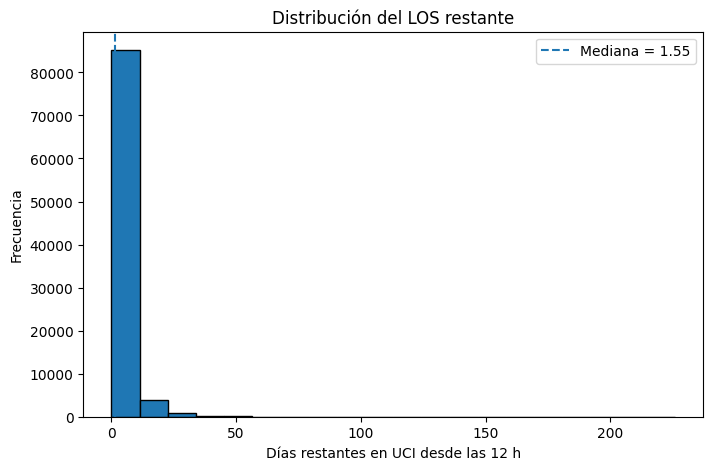

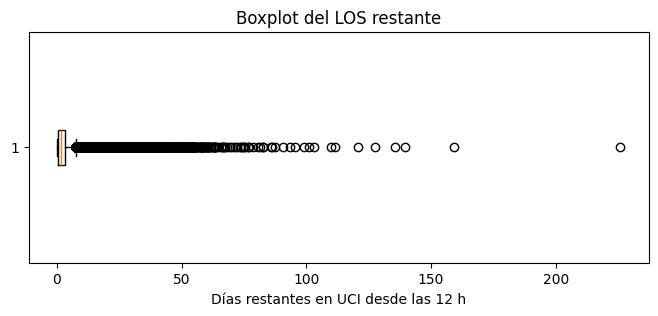

In [21]:
plt.figure(figsize=(8, 5))
plt.hist(y.dropna(), bins=20, edgecolor="black")
plt.axvline(y.median(), linestyle="--", label=f"Mediana = {y.median():.2f}")
plt.xlabel("Días restantes en UCI desde las 12 h")
plt.ylabel("Frecuencia")
plt.title("Distribución del LOS restante")
plt.legend()
plt.show()

plt.figure(figsize=(8, 3))
plt.boxplot(y.dropna(), vert=False)
plt.xlabel("Días restantes en UCI desde las 12 h")
plt.title("Boxplot del LOS restante")
plt.show()


## 8.2 Variables basales y categóricas


In [22]:
edad = dataset_modelo["edad_ingreso"]
resumen_edad = pd.DataFrame({
    "n": [edad.count()], "faltantes": [edad.isna().sum()],
    "media": [edad.mean()], "desv_std": [edad.std()],
    "minimo": [edad.min()], "p25": [edad.quantile(.25)],
    "mediana": [edad.median()], "p75": [edad.quantile(.75)],
    "maximo": [edad.max()], "IQR": [edad.quantile(.75)-edad.quantile(.25)],
    "asimetria": [edad.skew()]
})
display(resumen_edad.round(2))

for var in ["gender", "first_careunit", "admission_type", "admission_location"]:
    tabla = dataset_modelo[var].value_counts(dropna=False).rename_axis(var).reset_index(name="frecuencia")
    tabla["porcentaje"] = tabla["frecuencia"] / len(dataset_modelo) * 100
    print(f"\n===== {var.upper()} =====")
    display(tabla.round(2))


,n,faltantes,media,desv_std,minimo,p25,mediana,p75,maximo,IQR,asimetria
0,90467,0,64.8,16.64,18,55.0,66.0,77.0,103,22.0,-0.54



===== GENDER =====


,gender,frecuencia,porcentaje
0,M,50732,56.08
1,F,39735,43.92



===== FIRST_CAREUNIT =====


,first_careunit,frecuencia,porcentaje
0,Medical Intensive Care Unit (MICU),19744,21.82
1,Medical/Surgical Intensive Care Unit (MICU/SICU),14656,16.20
2,Cardiac Vascular Intensive Care Unit (CVICU),14461,15.98
3,Surgical Intensive Care Unit (SICU),12509,13.83
4,Coronary Care Unit (CCU),10214,11.29
5,Trauma SICU (TSICU),9840,10.88
6,Neuro Intermediate,5646,6.24
7,Neuro Surgical Intensive Care Unit (Neuro SICU),1696,1.87
8,Neuro Stepdown,1384,1.53
9,Surgery/Vascular/Intermediate,144,0.16



===== ADMISSION_TYPE =====


,admission_type,frecuencia,porcentaje
0,EW EMER.,46066,50.92
1,URGENT,14774,16.33
2,OBSERVATION ADMIT,13482,14.90
3,SURGICAL SAME DAY ADMISSION,9367,10.35
4,DIRECT EMER.,3199,3.54
5,ELECTIVE,2977,3.29
6,EU OBSERVATION,413,0.46
7,DIRECT OBSERVATION,172,0.19
8,AMBULATORY OBSERVATION,17,0.02



===== ADMISSION_LOCATION =====


,admission_location,frecuencia,porcentaje
0,EMERGENCY ROOM,35710,39.47
1,TRANSFER FROM HOSPITAL,23314,25.77
2,PHYSICIAN REFERRAL,22948,25.37
3,WALK-IN/SELF REFERRAL,4248,4.70
4,TRANSFER FROM SKILLED NURSING FACILITY,1416,1.57
5,CLINIC REFERRAL,1131,1.25
6,PROCEDURE SITE,991,1.10
7,PACU,395,0.44
8,INFORMATION NOT AVAILABLE,223,0.25
9,AMBULATORY SURGERY TRANSFER,67,0.07


## 8.3 Resumen de predictores numéricos


In [23]:
identificadores = ["subject_id", "hadm_id", "stay_id"]
excluir = identificadores + ["los", "los_restante_dias"]

variables_numericas = (
    dataset_modelo.select_dtypes(include="number").columns
    .difference(excluir).tolist()
)

resumen_numericas = pd.DataFrame({
    "n": dataset_modelo[variables_numericas].count(),
    "faltantes": dataset_modelo[variables_numericas].isna().sum(),
    "faltantes_%": dataset_modelo[variables_numericas].isna().mean() * 100,
    "media": dataset_modelo[variables_numericas].mean(),
    "desv_std": dataset_modelo[variables_numericas].std(),
    "minimo": dataset_modelo[variables_numericas].min(),
    "p25": dataset_modelo[variables_numericas].quantile(.25),
    "mediana": dataset_modelo[variables_numericas].median(),
    "p75": dataset_modelo[variables_numericas].quantile(.75),
    "maximo": dataset_modelo[variables_numericas].max(),
    "asimetria": dataset_modelo[variables_numericas].skew()
})
resumen_numericas["IQR"] = resumen_numericas["p75"] - resumen_numericas["p25"]
display(resumen_numericas.round(2))


,n,faltantes,faltantes_%,media,desv_std,minimo,p25,mediana,p75,maximo,asimetria,IQR
edad_ingreso,90467,0,0.00,64.80,16.64,18.00,55.00,66.00,77.00,103.00,-0.54,22.00
fc_max,90356,111,0.12,99.66,39.10,30.00,85.00,97.00,112.00,8400.00,133.89,27.00
fc_mean,90356,111,0.12,85.21,17.07,27.21,73.27,83.36,95.92,724.08,1.06,22.66
fc_min,90356,111,0.12,73.51,16.48,0.00,62.00,72.00,84.00,166.00,0.27,22.00
fr_max,90078,389,0.43,136.37,24676.49,0.00,22.00,25.00,29.00,7000400.00,263.22,7.00
...,...,...,...,...,...,...,...,...,...,...,...,...
spo2_mean,90290,177,0.20,98.47,309.19,34.43,95.67,97.25,98.75,81824.00,236.73,3.08
spo2_min,90290,177,0.20,92.97,6.27,-272.00,91.00,94.00,96.00,100.00,-7.90,5.00
temperatura_max,83080,7387,8.17,99.14,36.76,0.00,98.20,98.60,99.30,9834.00,227.22,1.10
temperatura_mean,83080,7387,8.17,98.26,12.01,0.00,97.80,98.22,98.70,3343.23,239.23,0.90


## 8.4 Asociación exploratoria con el objetivo


In [24]:
# Spearman se usa únicamente para describir asociación monotónica.
# NO se usa aquí para seleccionar o descartar predictores.
resultados_spearman = []
for variable in variables_numericas:
    datos = dataset_modelo[[variable, "los_restante_dias"]].dropna()
    if len(datos) >= 3 and datos[variable].nunique() > 1:
        rho, p_valor = spearmanr(datos[variable], datos["los_restante_dias"])
    else:
        rho, p_valor = np.nan, np.nan
    resultados_spearman.append({
        "variable": variable,
        "n": len(datos),
        "rho_spearman": rho,
        "p_valor": p_valor
    })

resultados_spearman = pd.DataFrame(resultados_spearman)
resultados_spearman["rho_abs"] = resultados_spearman["rho_spearman"].abs()
resultados_spearman = resultados_spearman.sort_values("rho_abs", ascending=False)
display(resultados_spearman.round(4))


,variable,n,rho_spearman,p_valor,rho_abs
67,lab_50894_calculated_free_testosterone,3,1.0,0.0,1.0
472,lab_52263_lining_cell,3,1.0,0.0,1.0
70,lab_50898_cancer_antigen_27_29,3,-1.0,0.0,1.0
287,lab_51272_protein_s_antigen,3,-1.0,0.0,1.0
233,lab_51174_cd3,3,-1.0,0.0,1.0
...,...,...,...,...,...
500,lab_53107_flua1,67,NaN,NaN,NaN
502,lab_53109_flub1,67,NaN,NaN,NaN
509,lab_53163_hiv_viral_load_ct,2,NaN,NaN,NaN
516,lab_53175_rdrp_ct,9,NaN,NaN,NaN


## 8.5 EDA específico de laboratorios


In [25]:
variables_laboratorio = columnas_labs

resumen_laboratorios = pd.DataFrame({
    "n": dataset_modelo[variables_laboratorio].count(),
    "faltantes": dataset_modelo[variables_laboratorio].isna().sum(),
    "faltantes_%": dataset_modelo[variables_laboratorio].isna().mean() * 100,
    "media": dataset_modelo[variables_laboratorio].mean(),
    "desv_std": dataset_modelo[variables_laboratorio].std(),
    "minimo": dataset_modelo[variables_laboratorio].min(),
    "Q1": dataset_modelo[variables_laboratorio].quantile(.25),
    "mediana": dataset_modelo[variables_laboratorio].median(),
    "Q3": dataset_modelo[variables_laboratorio].quantile(.75),
    "maximo": dataset_modelo[variables_laboratorio].max(),
    "asimetria": dataset_modelo[variables_laboratorio].skew(),
    "curtosis": dataset_modelo[variables_laboratorio].kurt()
}).sort_values("faltantes_%")

display(resumen_laboratorios.round(2))


,n,faltantes,faltantes_%,media,desv_std,minimo,Q1,mediana,Q3,maximo,asimetria,curtosis
lab_50902_chloride,80247,10220,11.30,103.95,6.44,61.0,100.0,104.0,108.0,151.0,-0.31,1.88
lab_50912_creatinine,80077,10390,11.48,1.45,1.59,0.0,0.7,1.0,1.5,41.5,4.86,41.74
lab_51006_urea_nitrogen,80026,10441,11.54,26.48,22.28,1.0,13.0,19.0,32.0,263.0,2.47,8.43
lab_50882_bicarbonate,79934,10533,11.64,23.09,4.56,2.0,21.0,23.0,26.0,50.0,0.29,2.14
lab_50868_anion_gap,78895,11572,12.79,14.03,4.18,-4.0,11.0,14.0,16.0,65.0,1.34,4.98
...,...,...,...,...,...,...,...,...,...,...,...,...
lab_52283_promyelocytes,1,90466,100.00,2.00,NaN,2.0,2.0,2.0,2.0,2.0,NaN,NaN
lab_52268_mesothelial_cells,1,90466,100.00,1.00,NaN,1.0,1.0,1.0,1.0,1.0,NaN,NaN
lab_50921_estradiol,1,90466,100.00,14.00,NaN,14.0,14.0,14.0,14.0,14.0,NaN,NaN
lab_50940_hepatitis_b_surface_antibody,1,90466,100.00,7.90,NaN,7.9,7.9,7.9,7.9,7.9,NaN,NaN


# Análisis exploratorio del dataset integrado

In [26]:
# Estilo general para todas las gráficas
sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.05
)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 120,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False
})

# Paleta uniforme
COLOR_PRINCIPAL = "#3B82F6"
COLOR_SECUNDARIO = "#93C5FD"
COLOR_DESTACADO = "#EF4444"
COLOR_NEUTRO = "#64748B"

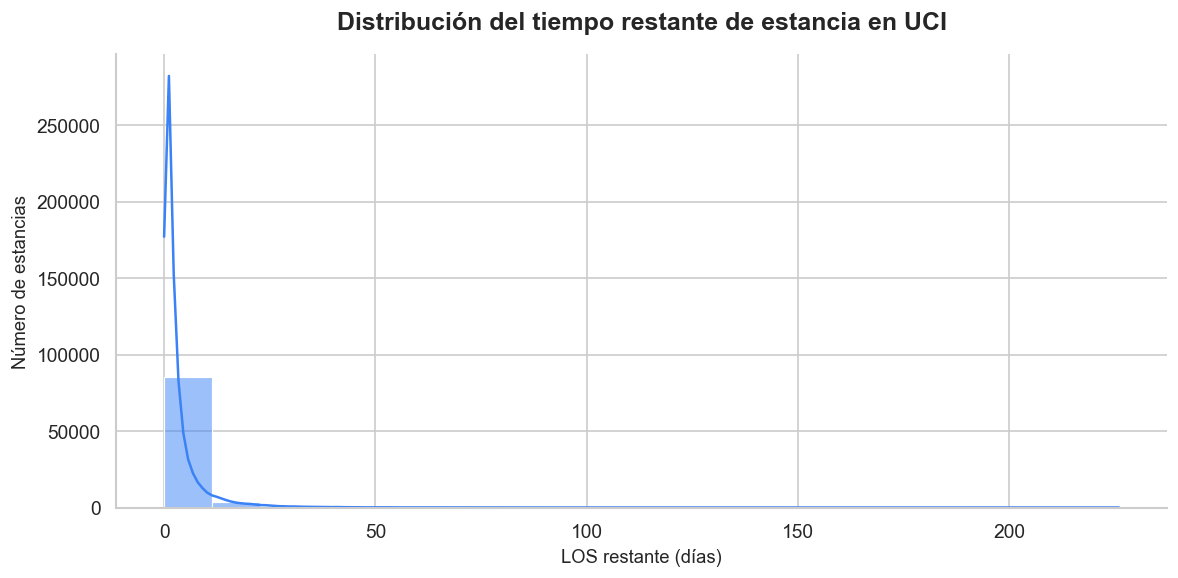

In [27]:
# Histograma del LOS restante
plt.figure(figsize=(10, 5))

sns.histplot(
    data=dataset_modelo,
    x="los_restante_dias",
    bins=20,
    kde=True,
    color=COLOR_PRINCIPAL,
    edgecolor="white",
    linewidth=0.7
)

plt.title("Distribución del tiempo restante de estancia en UCI", pad=15)
plt.xlabel("LOS restante (días)")
plt.ylabel("Número de estancias")

sns.despine()
plt.tight_layout()
plt.show()

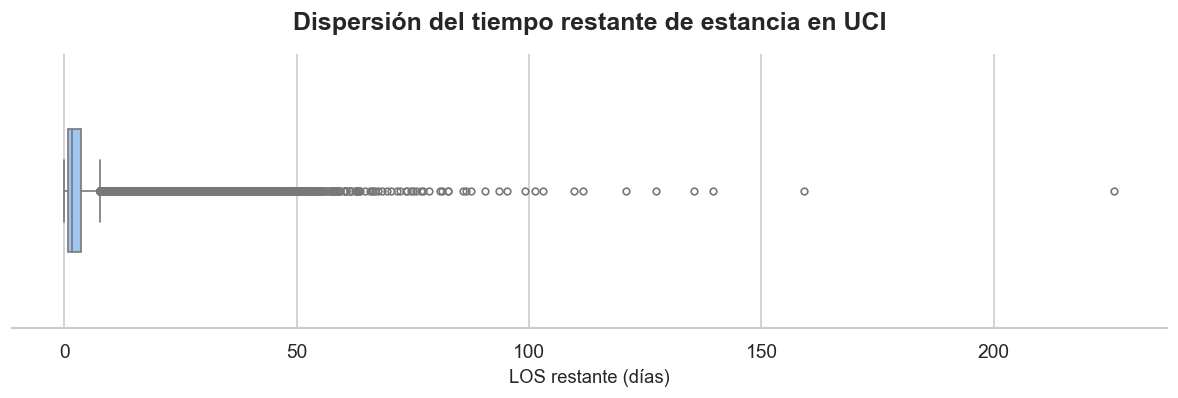

In [28]:
plt.figure(figsize=(10, 3.5))

sns.boxplot(
    data=dataset_modelo,
    x="los_restante_dias",
    color=COLOR_SECUNDARIO,
    width=0.45,
    fliersize=4
)

plt.title("Dispersión del tiempo restante de estancia en UCI", pad=15)
plt.xlabel("LOS restante (días)")
plt.ylabel("")

sns.despine(left=True)
plt.tight_layout()
plt.show()

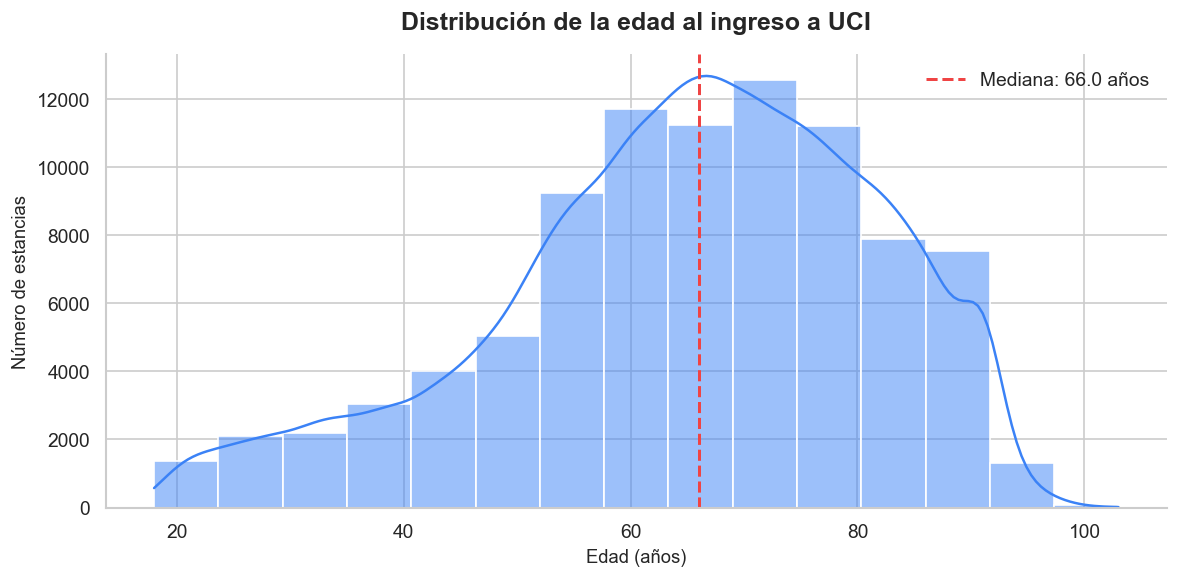

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=dataset_modelo,
    x="edad_ingreso",
    bins=15,
    kde=True,
    color=COLOR_PRINCIPAL,
    edgecolor="white"
)

plt.axvline(
    dataset_modelo["edad_ingreso"].median(),
    color=COLOR_DESTACADO,
    linestyle="--",
    linewidth=1.8,
    label=f'Mediana: {dataset_modelo["edad_ingreso"].median():.1f} años'
)

plt.title("Distribución de la edad al ingreso a UCI", pad=15)
plt.xlabel("Edad (años)")
plt.ylabel("Número de estancias")
plt.legend()

sns.despine()
plt.tight_layout()
plt.show()

In [31]:
def grafica_categorica(data, variable, titulo):

    tabla = (
        data[variable]
        .fillna("Sin información")
        .value_counts()
        .rename_axis("categoria")
        .reset_index(name="frecuencia")
    )

    tabla["porcentaje"] = (
        tabla["frecuencia"] / tabla["frecuencia"].sum() * 100
    )

    plt.figure(figsize=(10, max(4, len(tabla) * 0.55)))

    ax = sns.barplot(
        data=tabla,
        x="porcentaje",
        y="categoria",
        color=COLOR_PRINCIPAL
    )

    # Etiquetas con porcentaje y n
    for i, fila in tabla.iterrows():
        ax.text(
            fila["porcentaje"] + 0.5,
            i,
            f'{fila["porcentaje"]:.1f}%  (n={fila["frecuencia"]})',
            va="center",
            fontsize=9
        )

    plt.title(titulo, pad=15)
    plt.xlabel("Porcentaje de estancias (%)")
    plt.ylabel("")

    plt.xlim(
        0,
        tabla["porcentaje"].max() * 1.25
    )

    sns.despine()
    plt.tight_layout()
    plt.show()

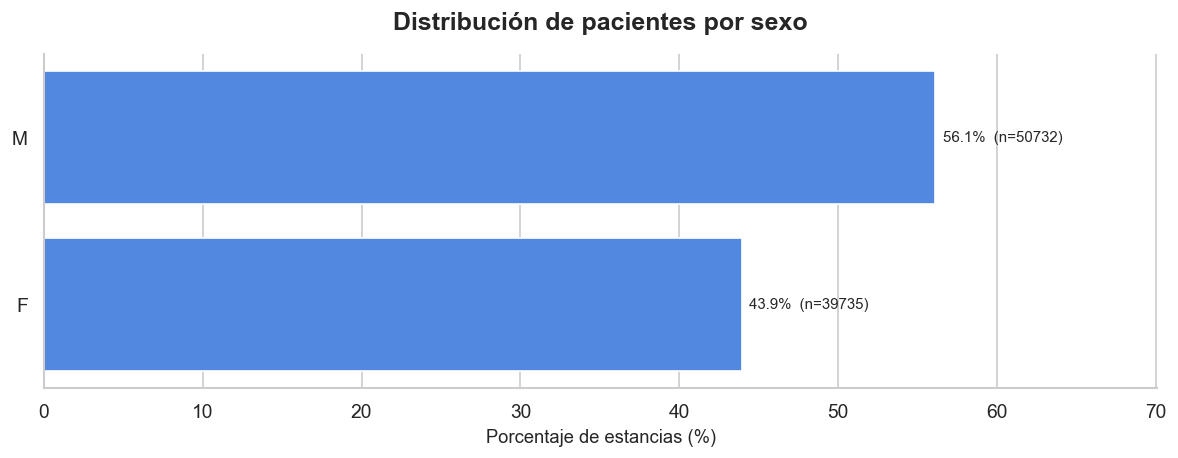

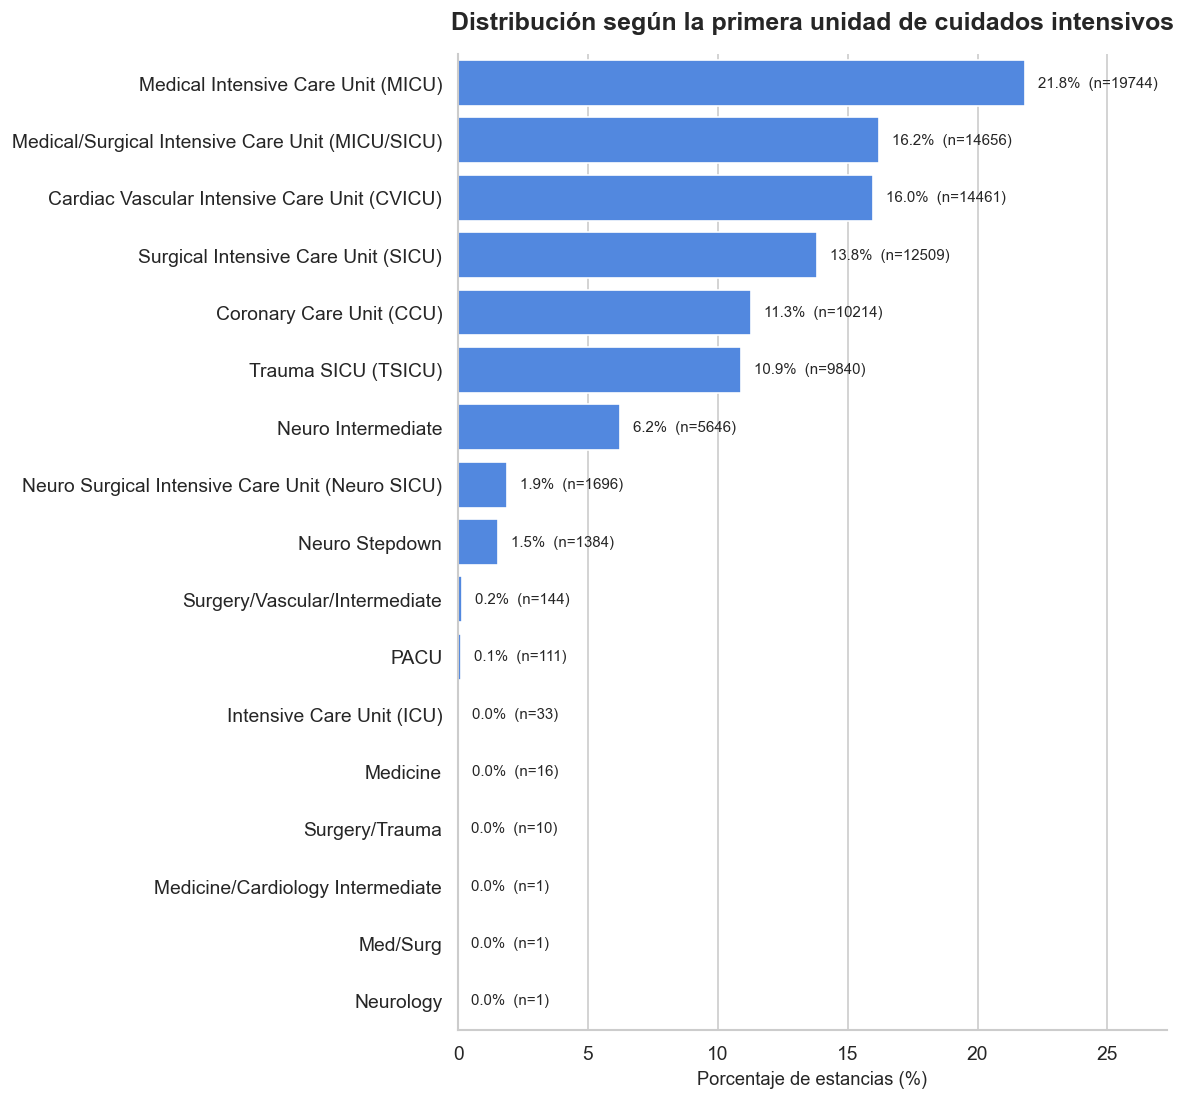

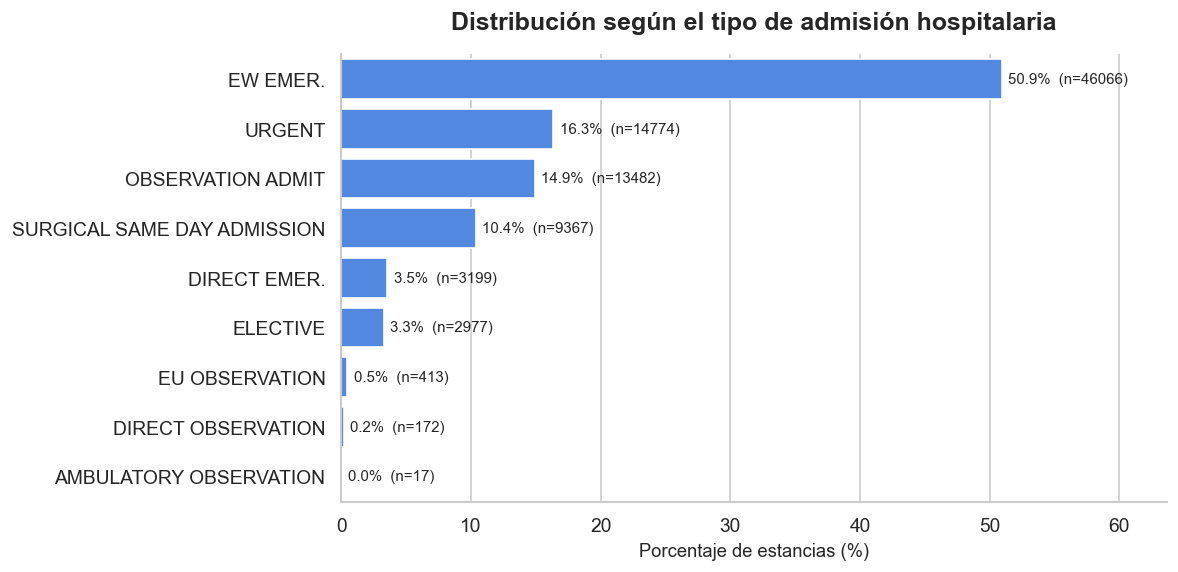

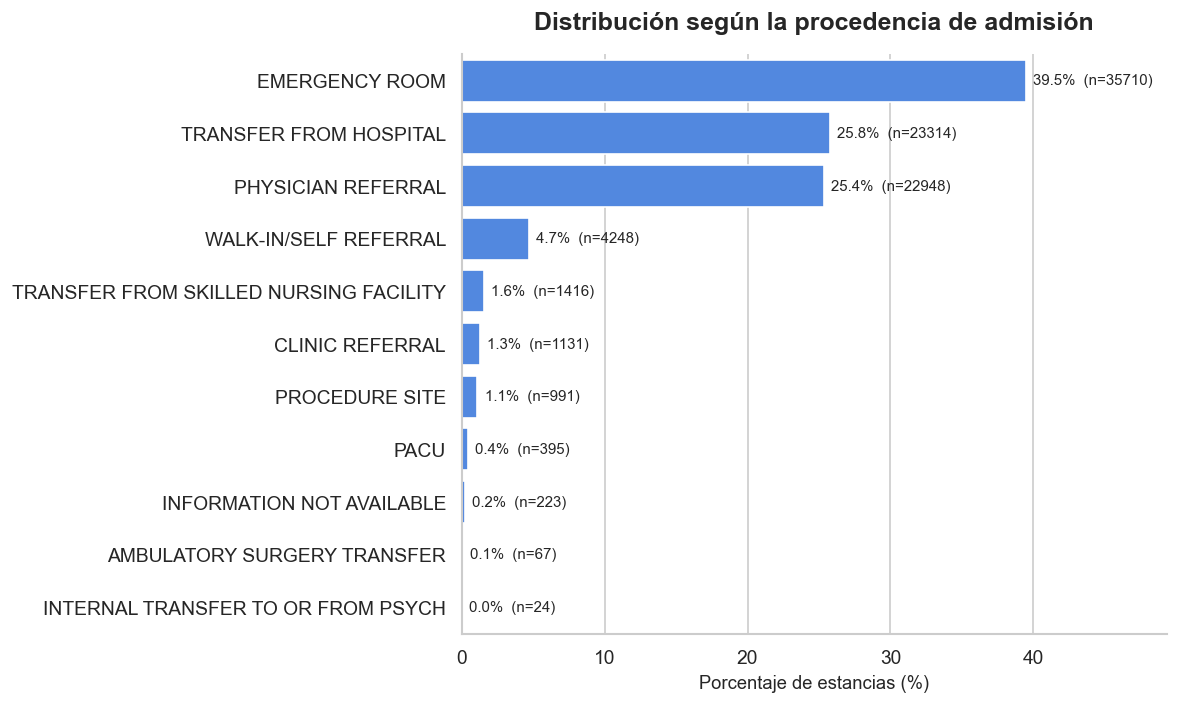

In [32]:
grafica_categorica(
    dataset_modelo,
    "gender",
    "Distribución de pacientes por sexo"
)

grafica_categorica(
    dataset_modelo,
    "first_careunit",
    "Distribución según la primera unidad de cuidados intensivos"
)

grafica_categorica(
    dataset_modelo,
    "admission_type",
    "Distribución según el tipo de admisión hospitalaria"
)

grafica_categorica(
    dataset_modelo,
    "admission_location",
    "Distribución según la procedencia de admisión"
)



In [33]:
faltantes = (
    dataset_modelo
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=True)
)

faltantes = faltantes[faltantes > 0]

plt.figure(
    figsize=(10, max(6, len(faltantes) * 0.32))
)

ax = sns.barplot(
    x=faltantes.values,
    y=faltantes.index,
    hue=faltantes.values,
    palette="Blues",
    legend=False
)

plt.title(
    "Porcentaje de valores faltantes por variable",
    pad=15
)

plt.xlabel("Valores faltantes (%)")
plt.ylabel("")

# Porcentaje al final de cada barra
for i, valor in enumerate(faltantes.values):
    ax.text(
        valor + 0.5,
        i,
        f"{valor:.1f}%",
        va="center",
        fontsize=8
    )

plt.xlim(0, max(faltantes.max() * 1.15, 10))

sns.despine()
plt.tight_layout()
plt.show()

In [34]:
# ============================================================
# ELIMINACIÓN DE VARIABLES CON MÁS DEL 45% DE DATOS FALTANTES
# ============================================================

UMBRAL_FALTANTES = 0.45   # 45%

# Columnas que queremos proteger del filtro
columnas_protegidas = [
    "subject_id",
    "hadm_id",
    "stay_id",
    "los",
    "los_restante_dias",
    "edad_ingreso",
    "gender",
    "first_careunit",
    "admission_type",
    "admission_location"
]

# Calcular proporción de valores faltantes
porcentaje_faltantes = dataset_modelo.isna().mean()

# Variables que superan el 45% de faltantes
variables_eliminar = [
    col for col in dataset_modelo.columns
    if col not in columnas_protegidas
    and porcentaje_faltantes[col] > UMBRAL_FALTANTES
]

print(f"Variables antes del filtro: {dataset_modelo.shape[1]}")
print(f"Variables a eliminar: {len(variables_eliminar)}")

print("\nVariables eliminadas:")
for col in variables_eliminar:
    print(
        f"{col}: {porcentaje_faltantes[col] * 100:.1f}% faltante"
    )

Variables antes del filtro: 544
Variables a eliminar: 490

Variables eliminadas:
lab_50801_alveolar_arterial_gradient: 97.2% faltante
lab_50802_base_excess: 48.8% faltante
lab_50803_calculated_bicarbonate_whole_blood: 98.5% faltante
lab_50804_calculated_total_co2: 48.8% faltante
lab_50805_carboxyhemoglobin: 99.6% faltante
lab_50806_chloride_whole_blood: 84.2% faltante
lab_50808_free_calcium: 68.1% faltante
lab_50809_glucose: 78.1% faltante
lab_50810_hematocrit_calculated: 83.0% faltante
lab_50811_hemoglobin: 83.0% faltante
lab_50813_lactate: 49.3% faltante
lab_50814_methemoglobin: 99.7% faltante
lab_50815_o2_flow: 98.2% faltante
lab_50816_oxygen: 90.7% faltante
lab_50817_oxygen_saturation: 78.6% faltante
lab_50818_pco2: 48.8% faltante
lab_50819_peep: 92.2% faltante
lab_50820_ph: 47.1% faltante
lab_50821_po2: 48.8% faltante
lab_50822_potassium_whole_blood: 77.4% faltante
lab_50823_required_o2: 97.2% faltante
lab_50824_sodium_whole_blood: 81.8% faltante
lab_50825_temperature: 87.5% falta

In [35]:
dataset_analitico = dataset_modelo.drop(
    columns=variables_eliminar
).copy()

print("\nDimensiones:")
print("Dataset integrado original:", dataset_modelo.shape)
print("Dataset analítico:", dataset_analitico.shape)


Dimensiones:
Dataset integrado original: (90467, 544)
Dataset analítico: (90467, 54)


In [36]:
faltantes_final = (
    dataset_analitico
    .isna()
    .mean()
    .mul(100)
    .sort_values()
)

faltantes_final[faltantes_final > 0]

fc_min                          0.122697
fc_mean                         0.122697
fc_max                          0.122697
spo2_max                        0.195651
spo2_mean                       0.195651
spo2_min                        0.195651
fr_mean                         0.429991
fr_max                          0.429991
fr_min                          0.429991
temperatura_mean                8.165408
temperatura_max                 8.165408
temperatura_min                 8.165408
lab_50902_chloride             11.296937
lab_50912_creatinine           11.484851
lab_51006_urea_nitrogen        11.541225
lab_50882_bicarbonate          11.642920
lab_50868_anion_gap            12.791405
lab_51221_hematocrit           13.127439
lab_50971_potassium            13.156178
lab_51265_platelet_count       14.015055
lab_51222_hemoglobin           14.135541
lab_51301_white_blood_cells    14.206285
lab_51279_red_blood_cells      14.253816
lab_51250_mcv                  14.254922
lab_51249_mchc  

In [37]:
nombres_variables = {
    "edad_ingreso": "Edad al ingreso",
    "los_restante_dias": "LOS restante",
    
    # Ejemplos de signos vitales
    "heart_rate_min": "Frecuencia cardiaca mínima",
    "heart_rate_mean": "Frecuencia cardiaca media",
    "heart_rate_max": "Frecuencia cardiaca máxima",
    
    "sbp_min": "Presión sistólica mínima",
    "sbp_mean": "Presión sistólica media",
    "sbp_max": "Presión sistólica máxima",
    
    "dbp_min": "Presión diastólica mínima",
    "dbp_mean": "Presión diastólica media",
    "dbp_max": "Presión diastólica máxima"
}

In [38]:
def nombre_legible(variable):
    return nombres_variables.get(
        variable,
        variable.replace("_", " ").title()
    )

In [39]:
def grafica_numerica(data, variable):

    nombre = nombre_legible(variable)

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 4)
    )

    # Histograma
    sns.histplot(
        data=data,
        x=variable,
        bins=20,
        kde=True,
        color=COLOR_PRINCIPAL,
        edgecolor="white",
        ax=axes[0]
    )

    mediana = data[variable].median()

    axes[0].axvline(
        mediana,
        color=COLOR_DESTACADO,
        linestyle="--",
        linewidth=1.5,
        label=f"Mediana: {mediana:.2f}"
    )

    axes[0].set_title(f"Distribución de {nombre}")
    axes[0].set_xlabel(nombre)
    axes[0].set_ylabel("Número de estancias")
    axes[0].legend()

    # Boxplot
    sns.boxplot(
        data=data,
        x=variable,
        color=COLOR_SECUNDARIO,
        width=0.45,
        fliersize=3,
        ax=axes[1]
    )

    axes[1].set_title(f"Dispersión de {nombre}")
    axes[1].set_xlabel(nombre)
    axes[1].set_ylabel("")

    sns.despine()

    fig.suptitle(
        nombre,
        fontsize=15,
        fontweight="bold",
        y=1.03
    )

    plt.tight_layout()
    plt.show()

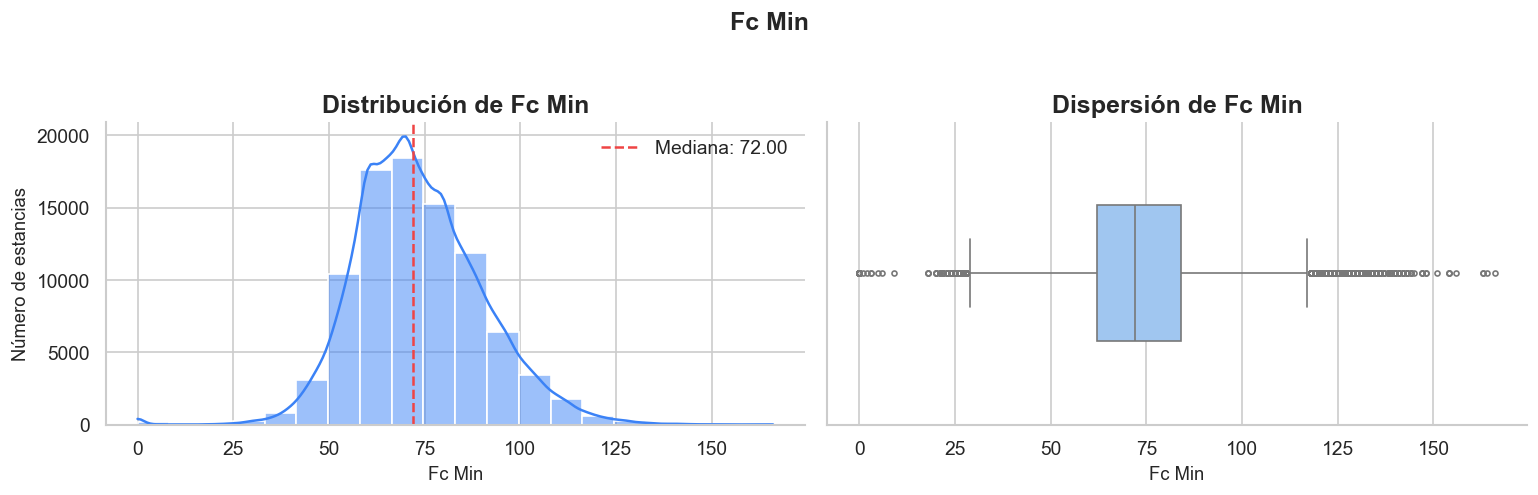

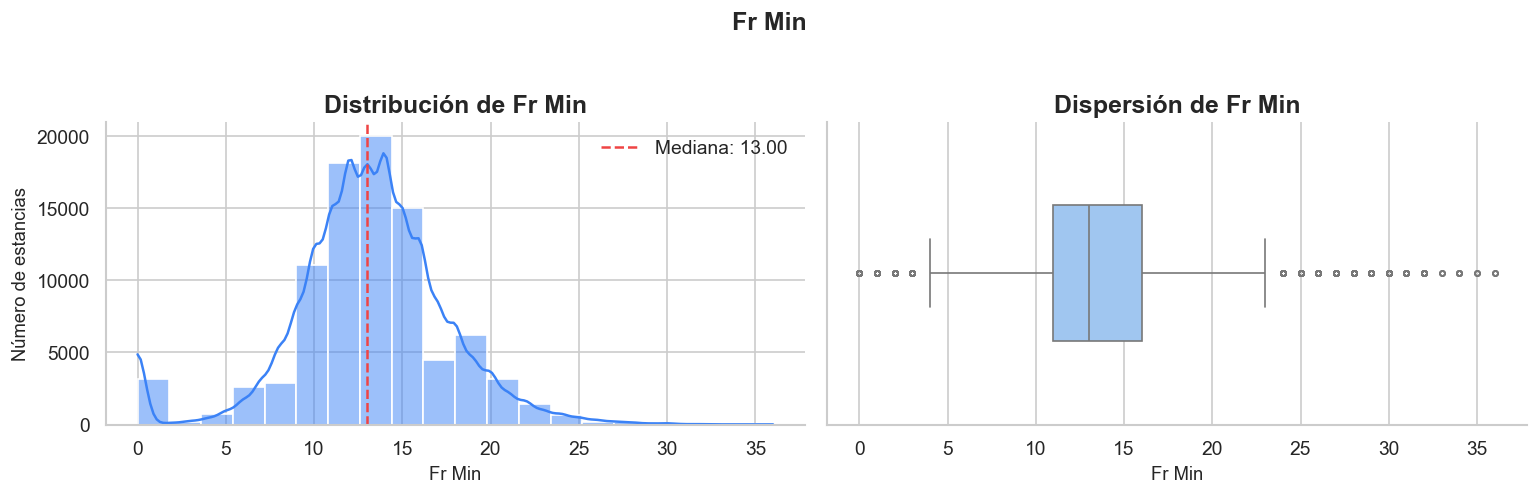

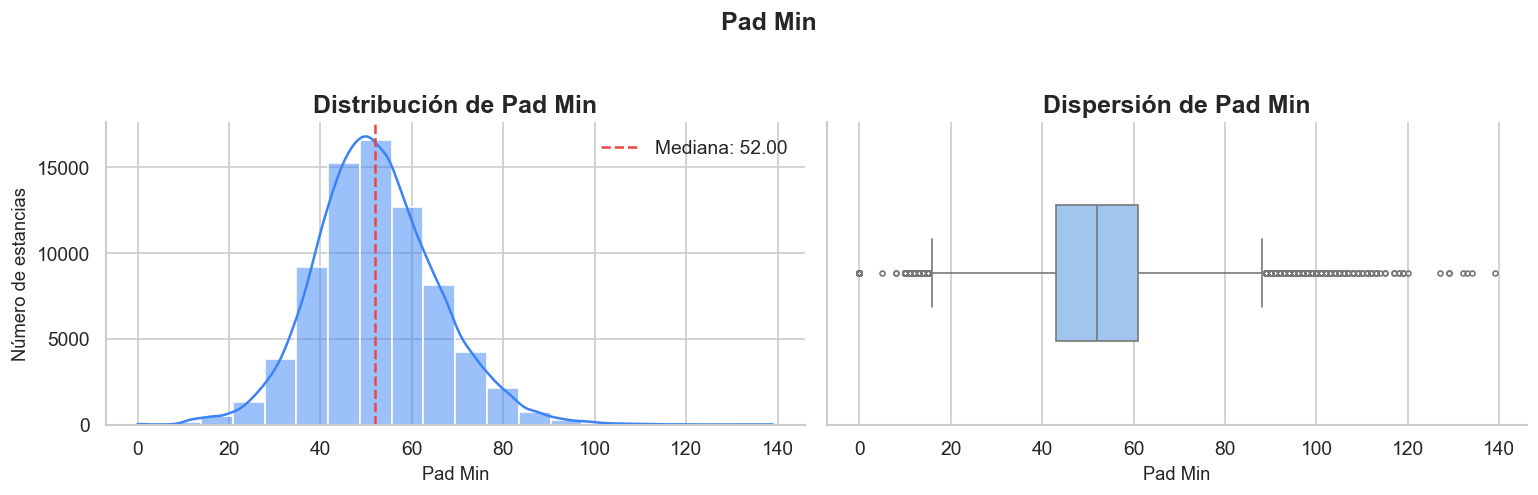

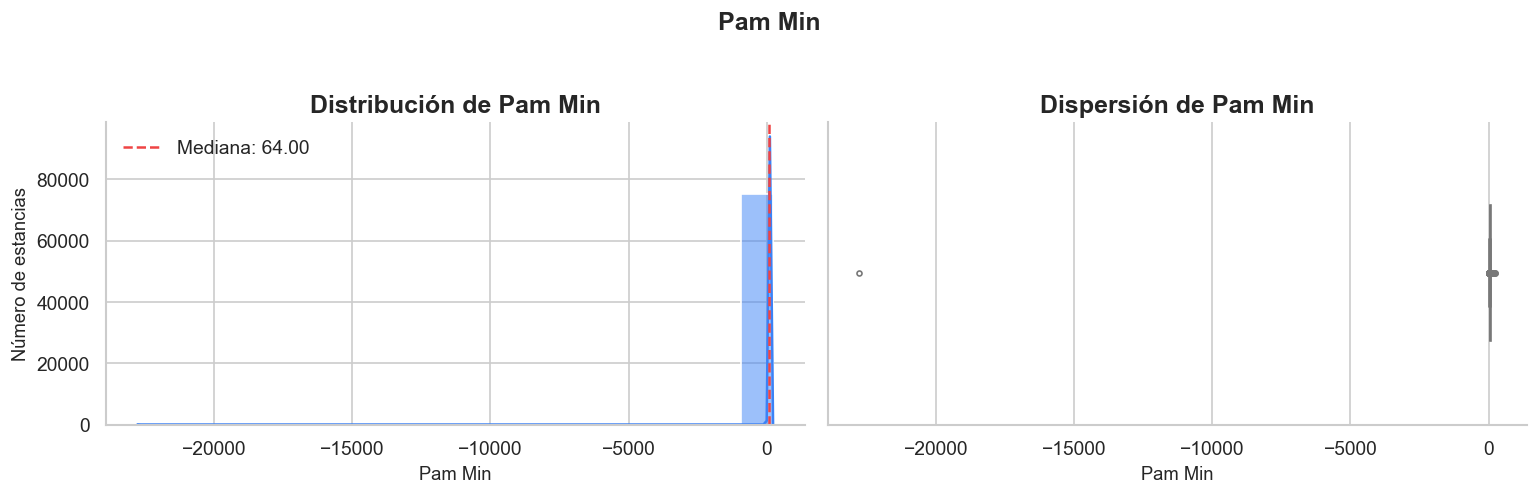

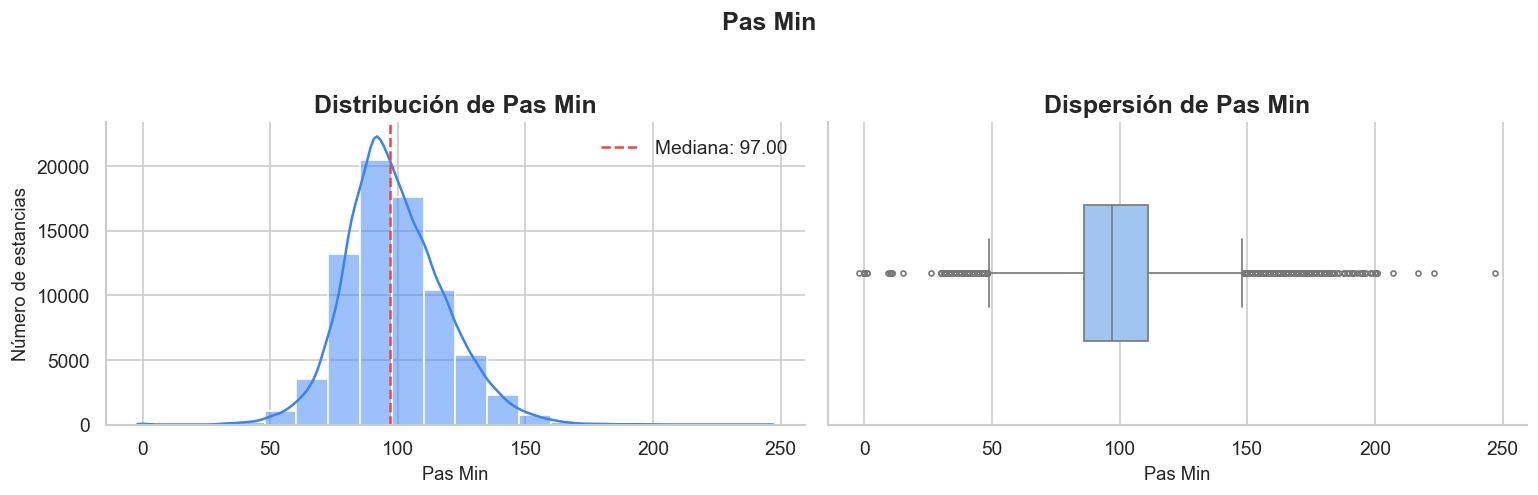

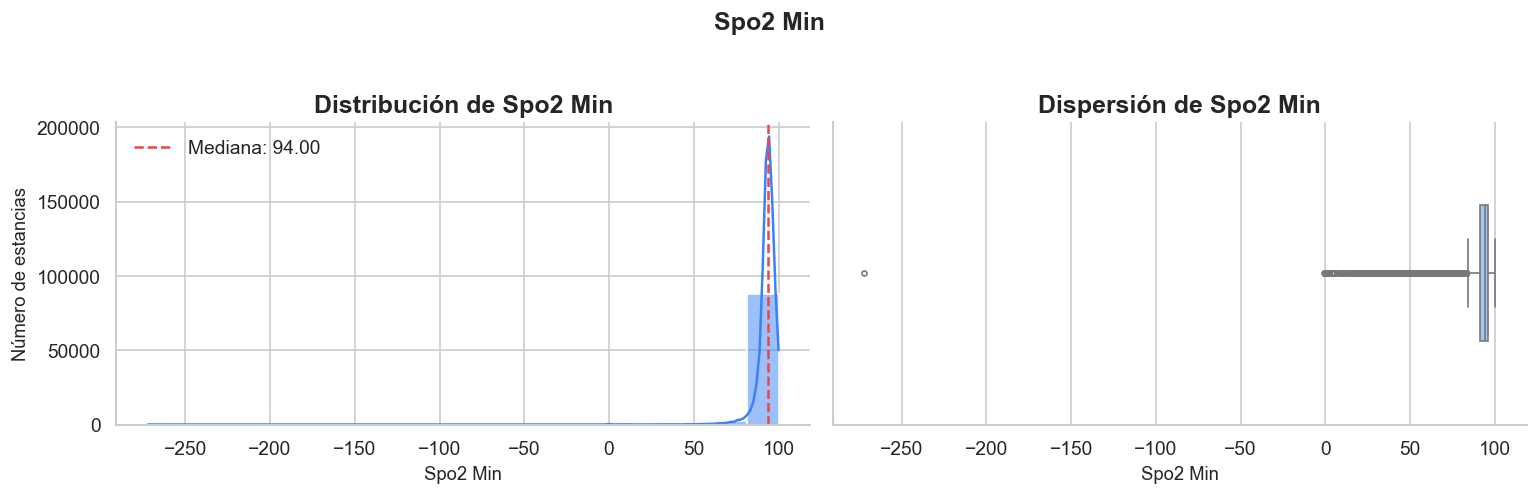

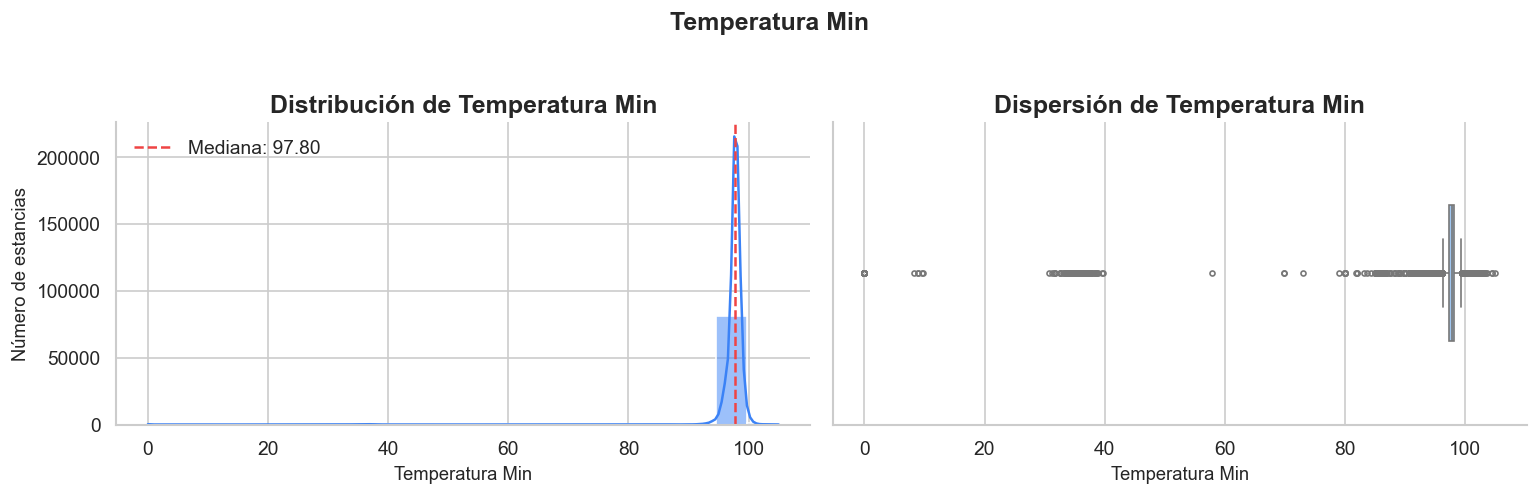

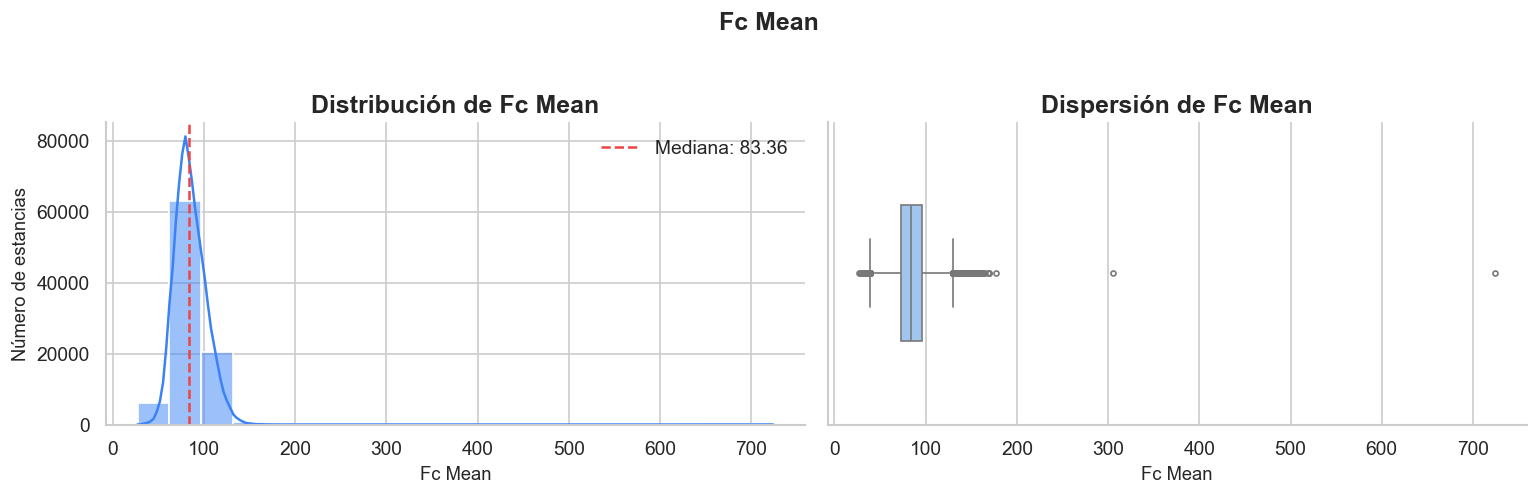

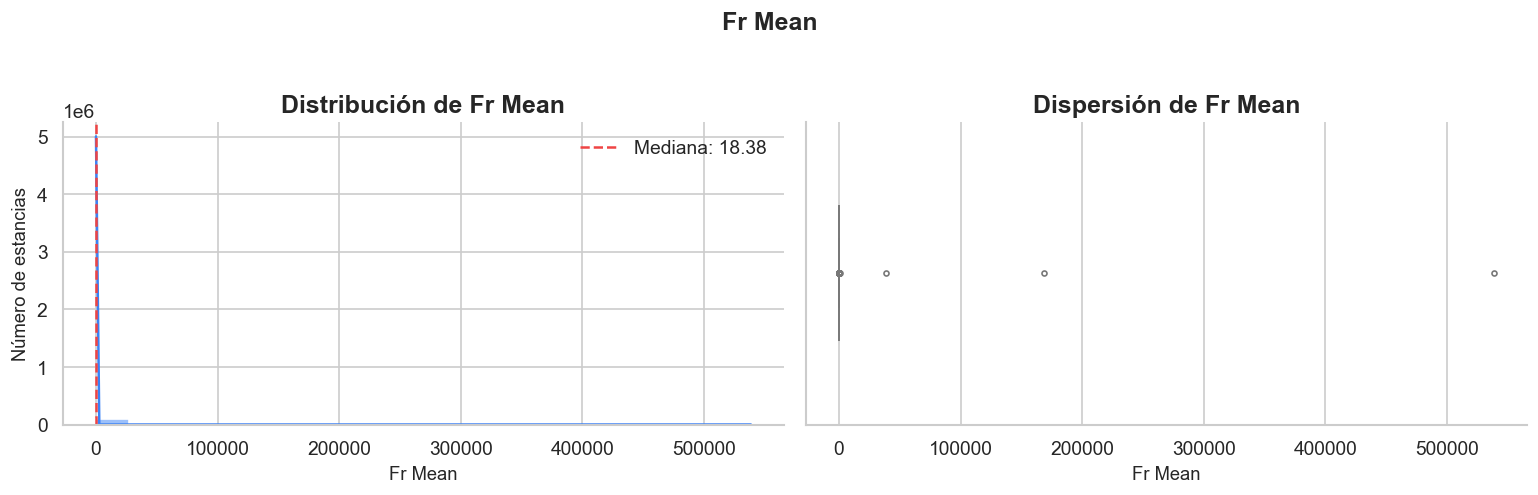

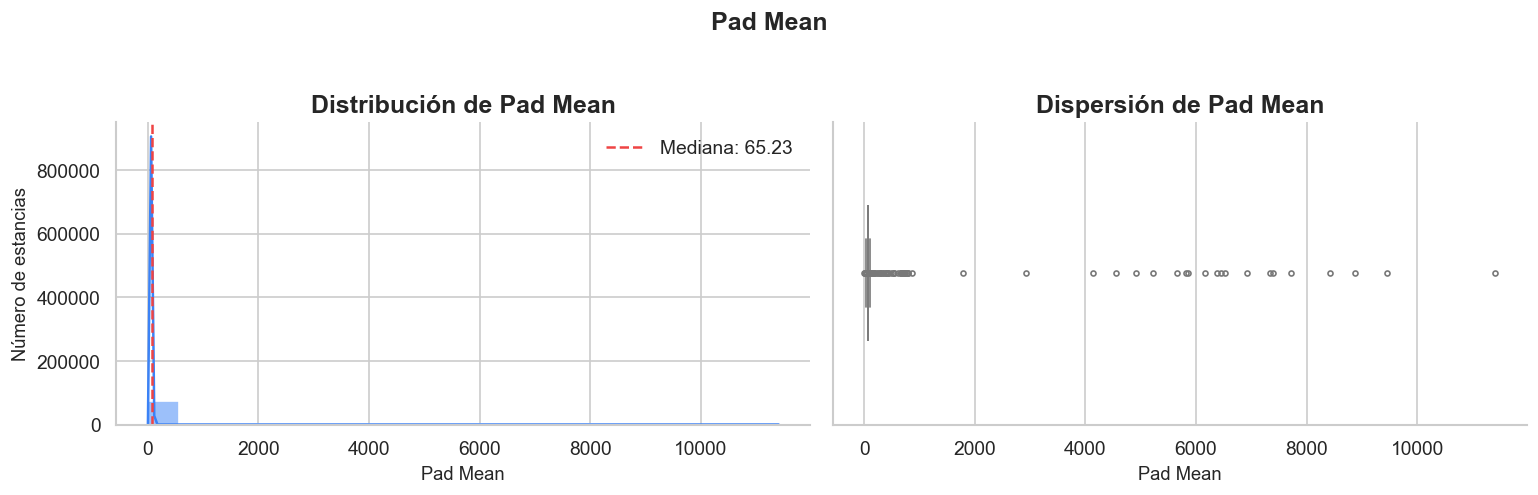

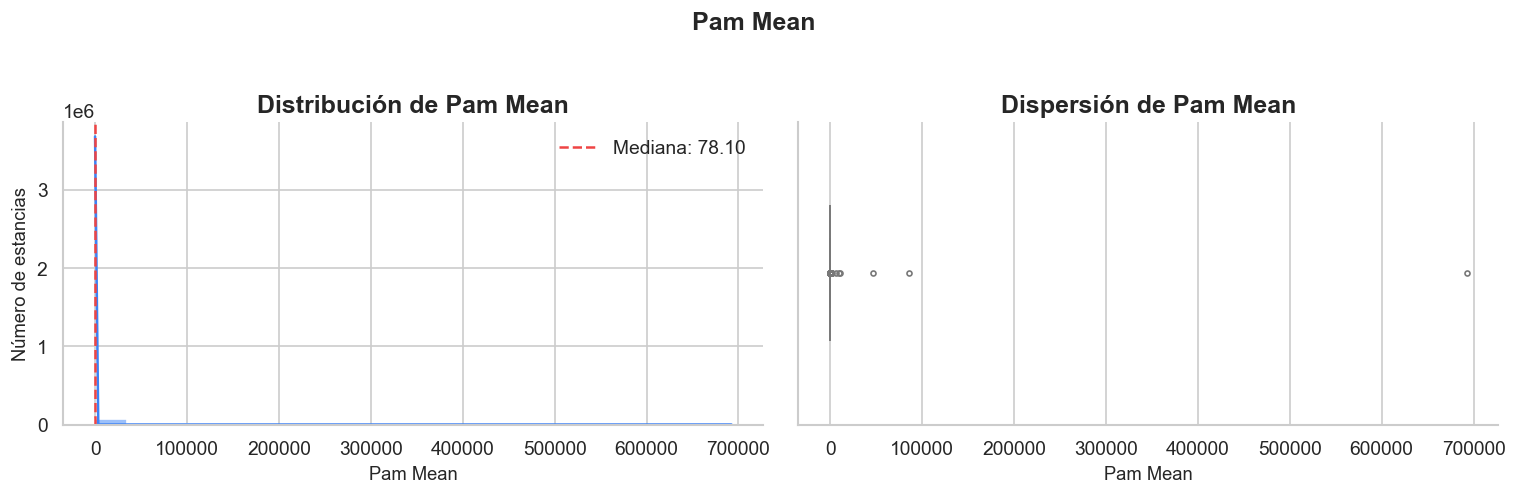

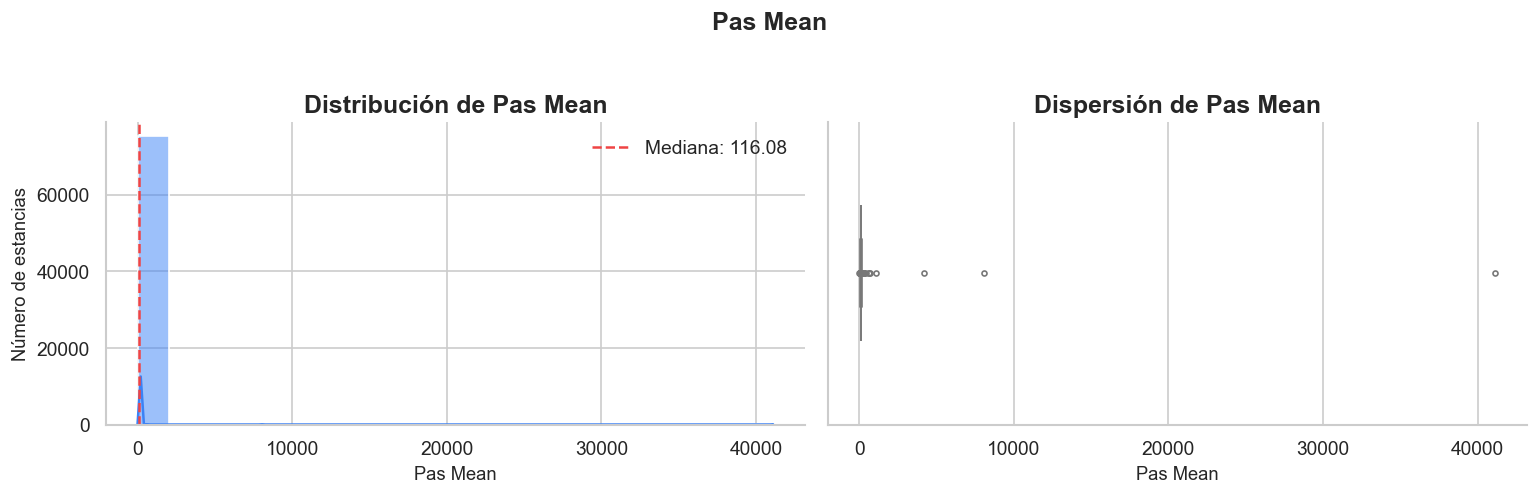

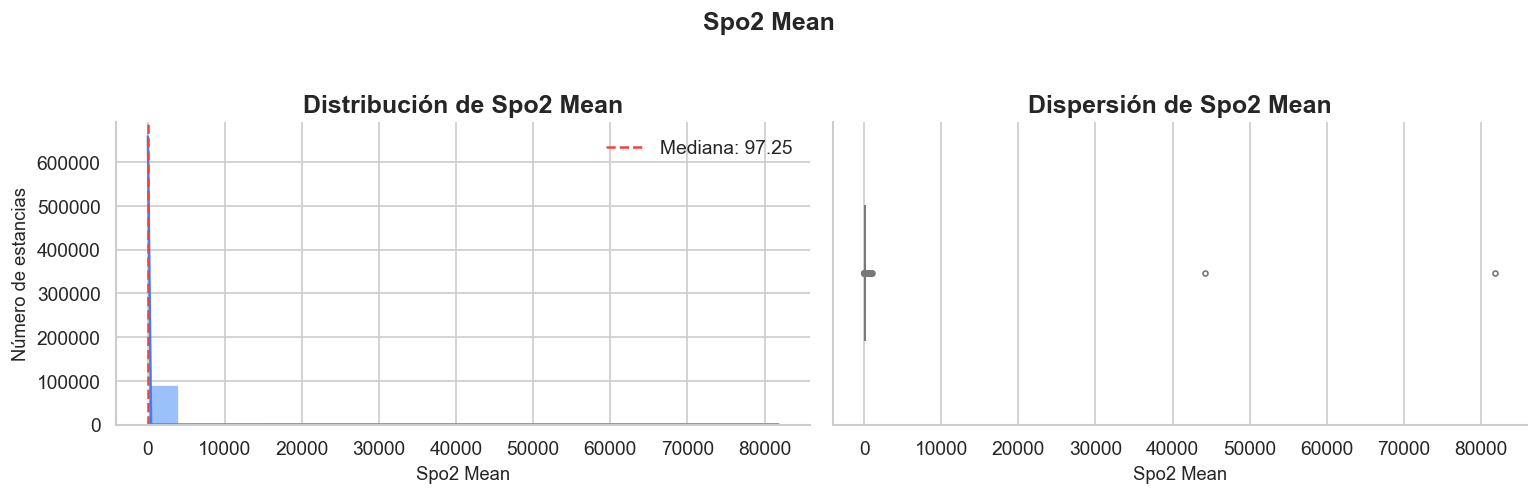

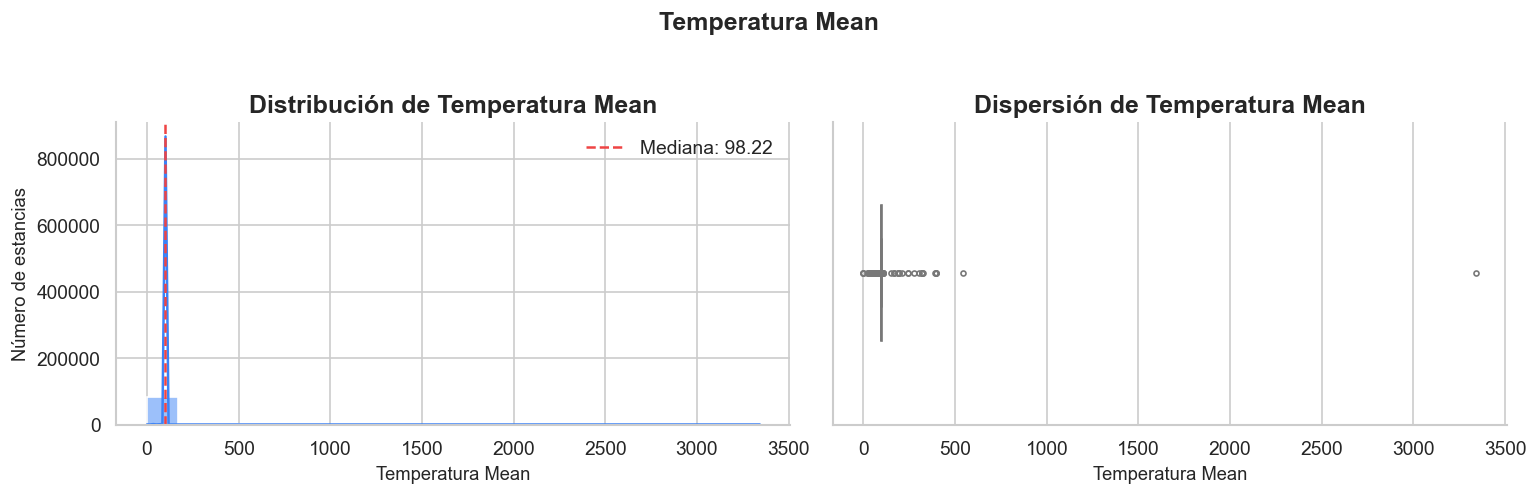

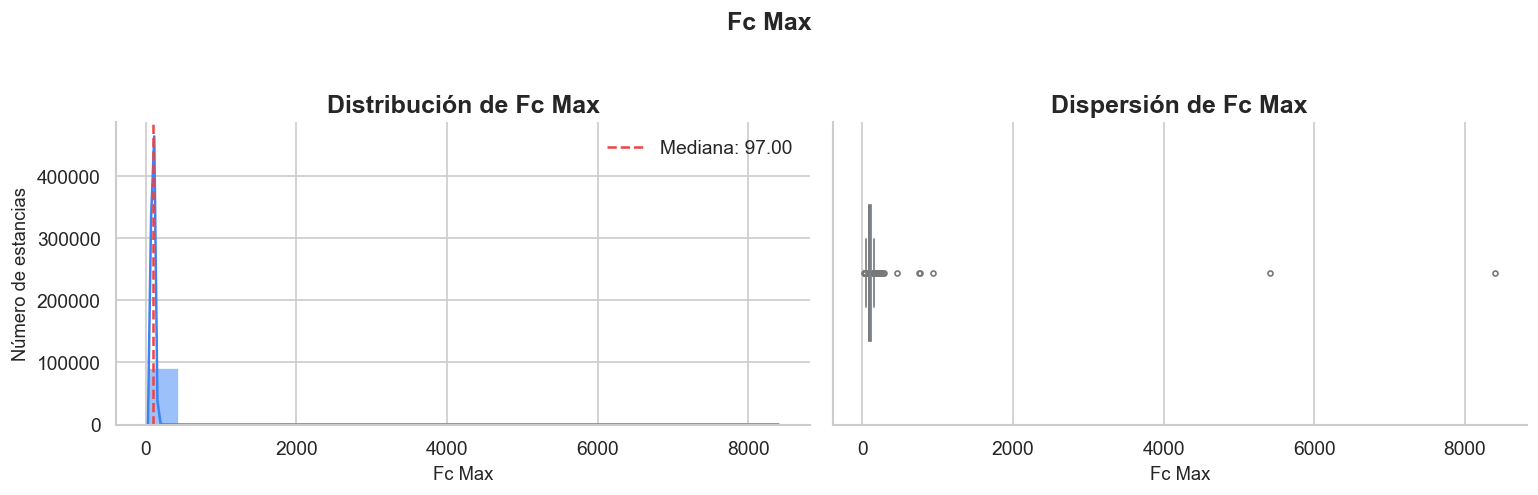

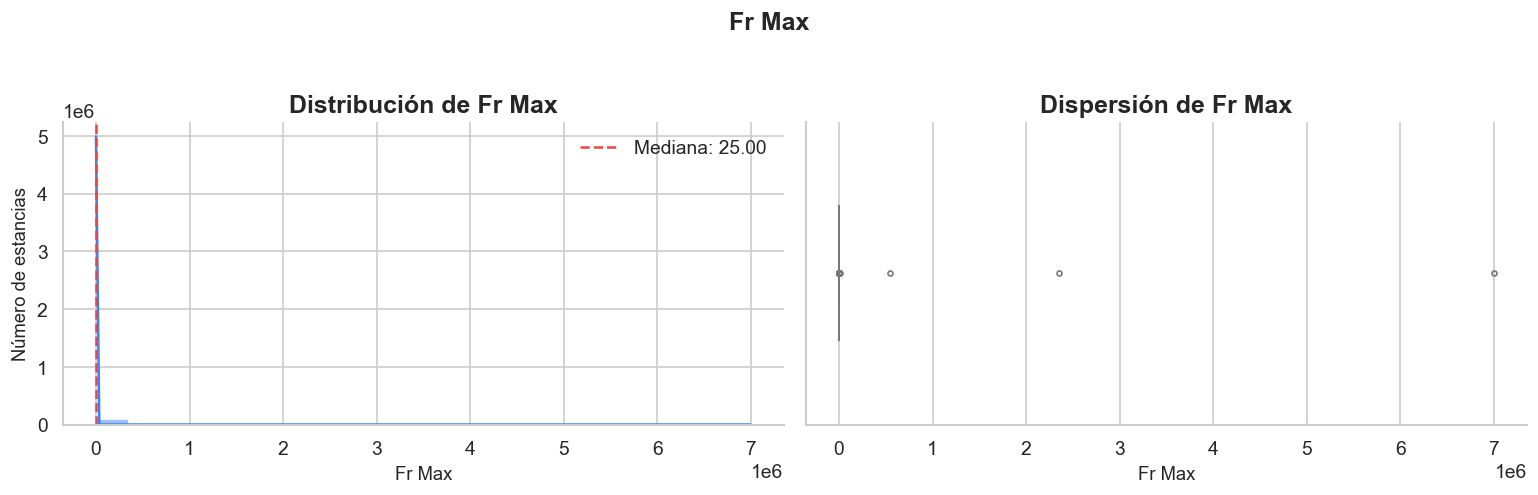

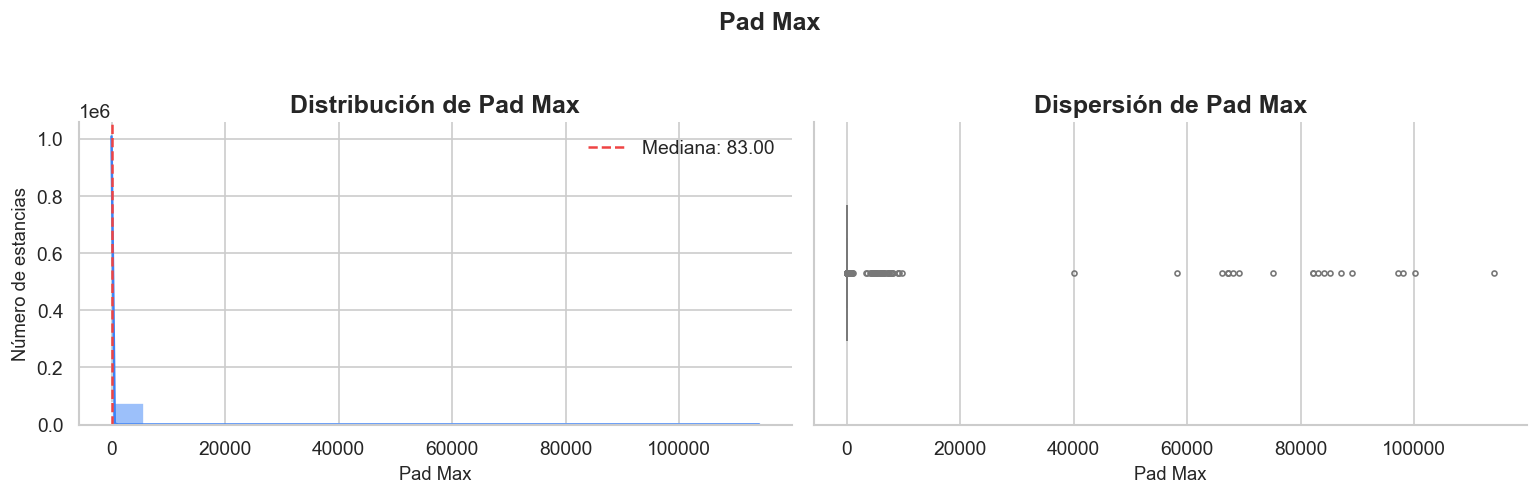

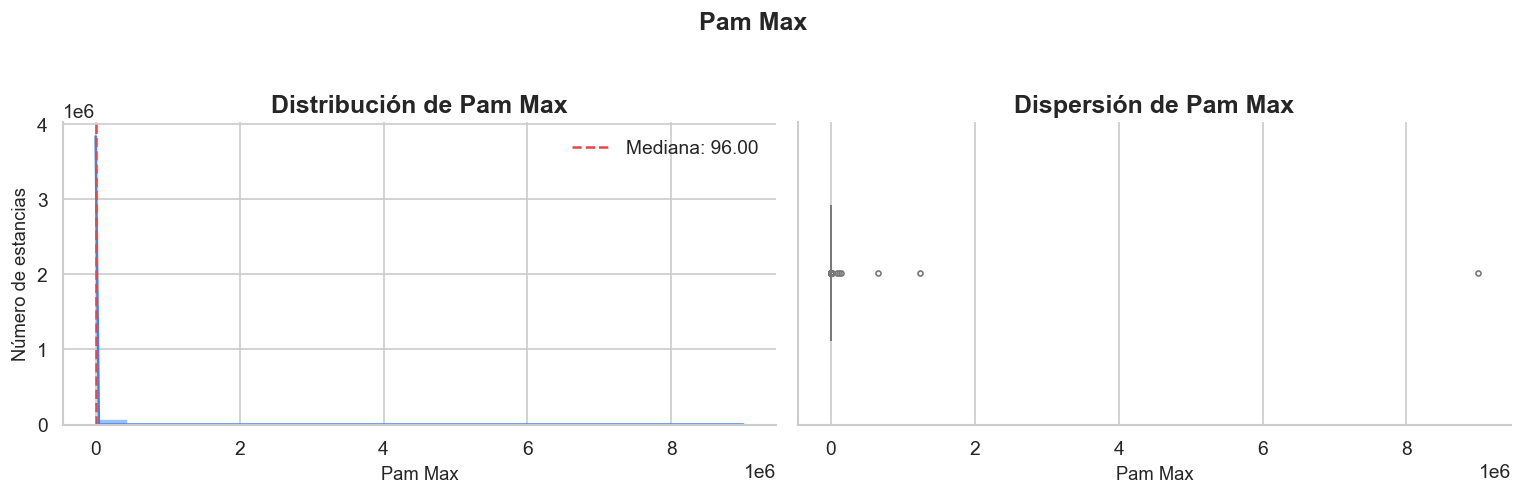

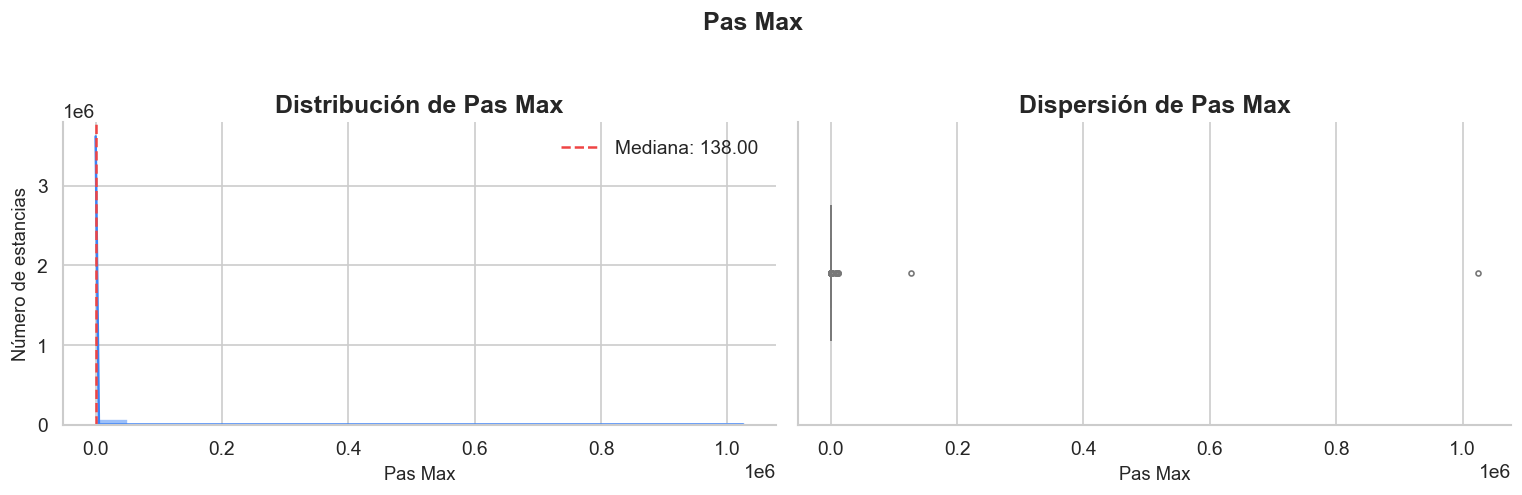

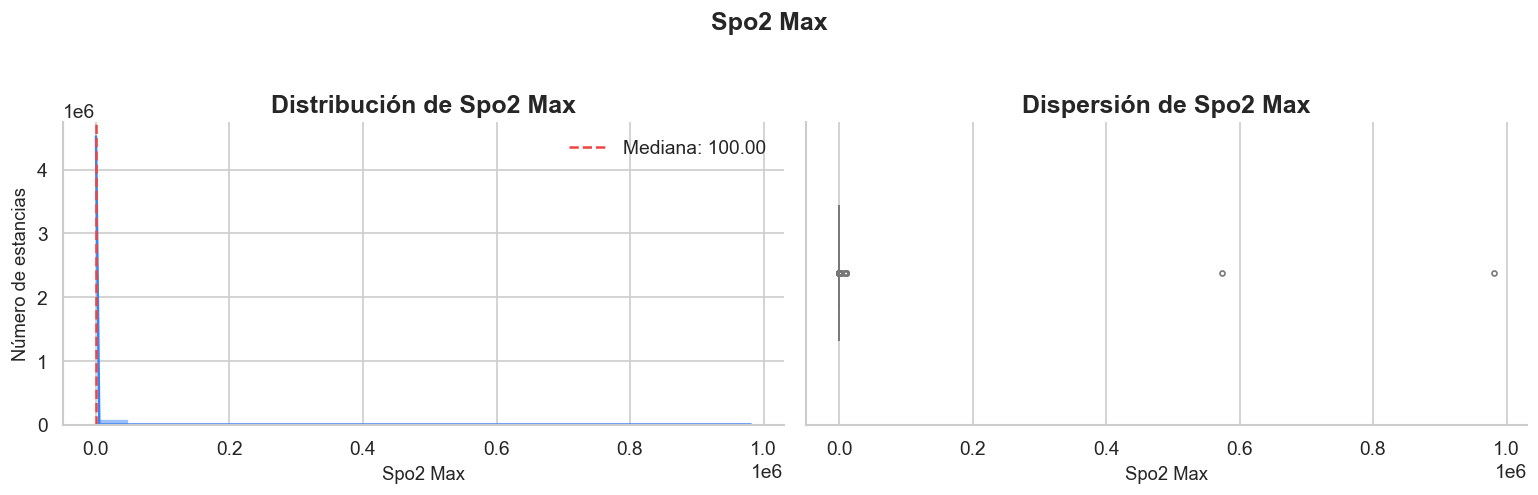

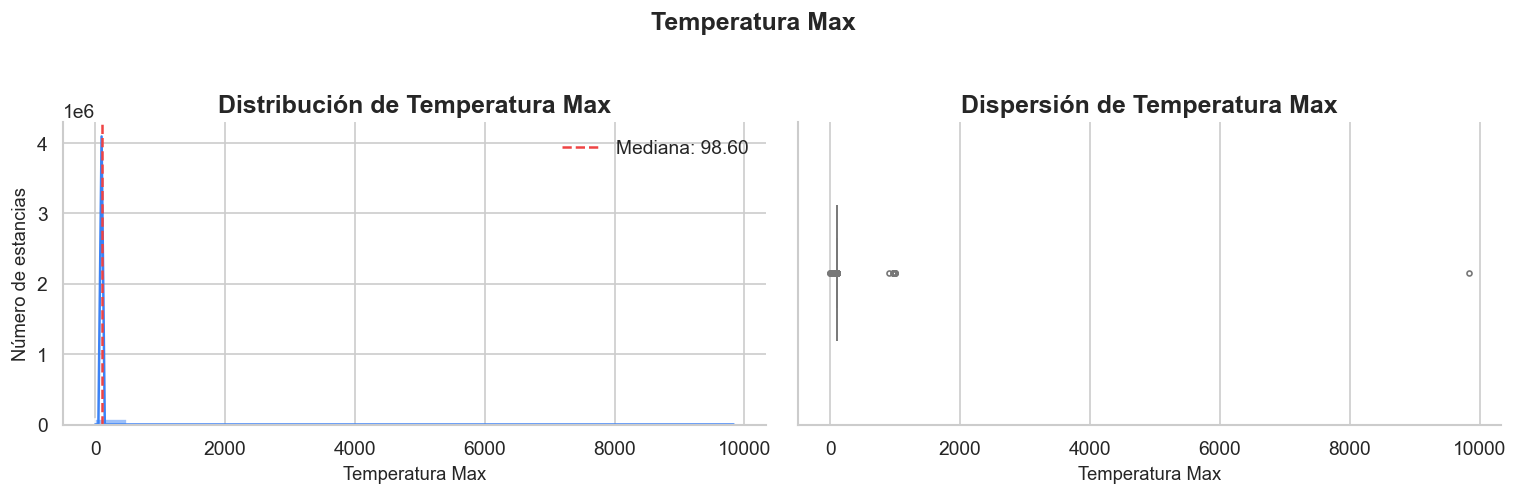

In [40]:
for variable in columnas_signos:
    grafica_numerica(dataset_analitico, variable)

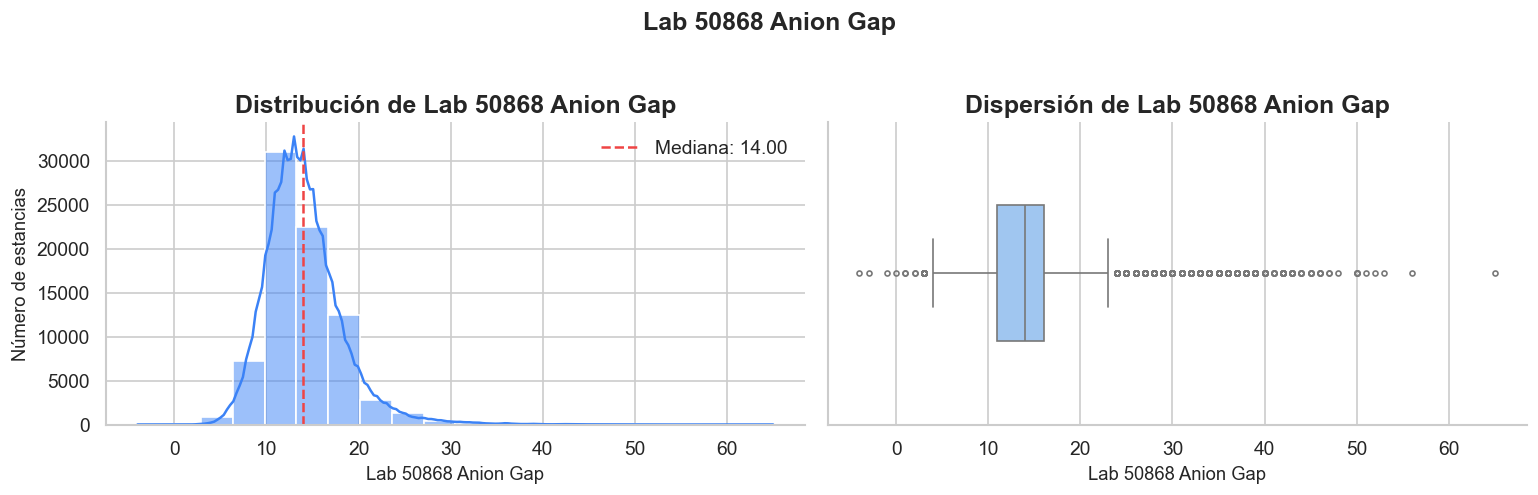

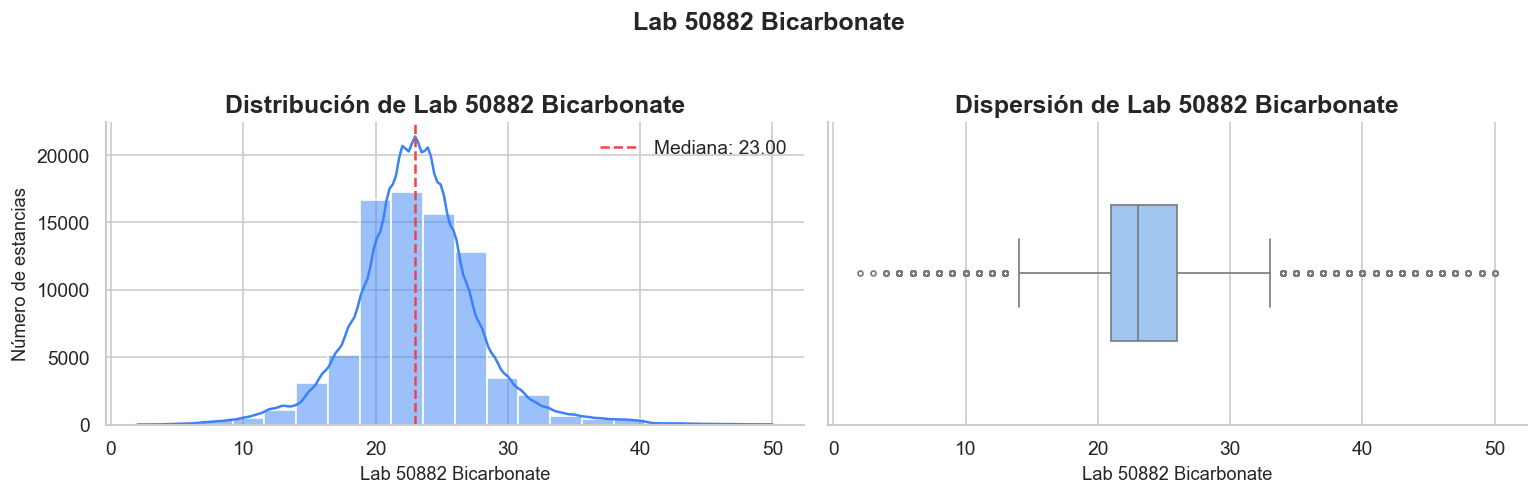

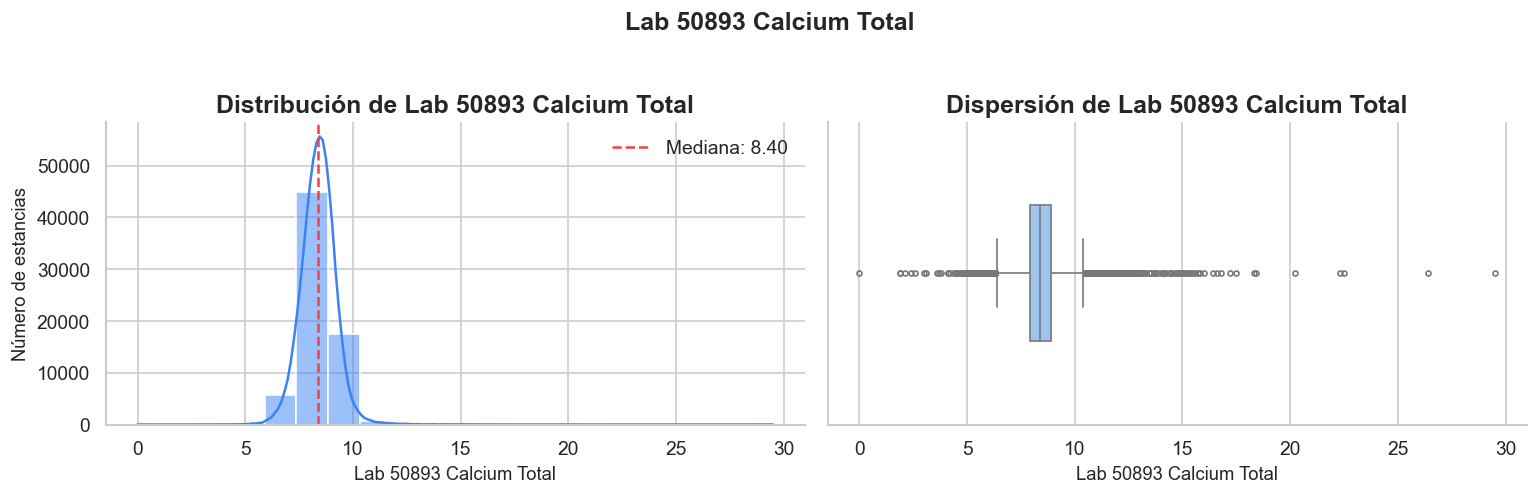

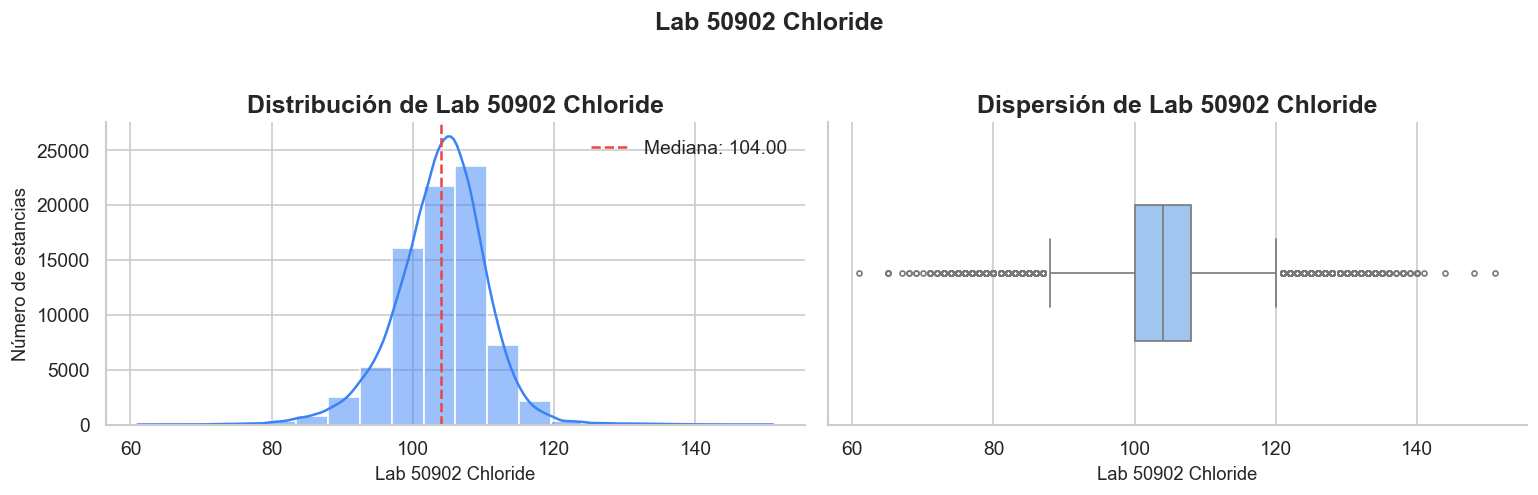

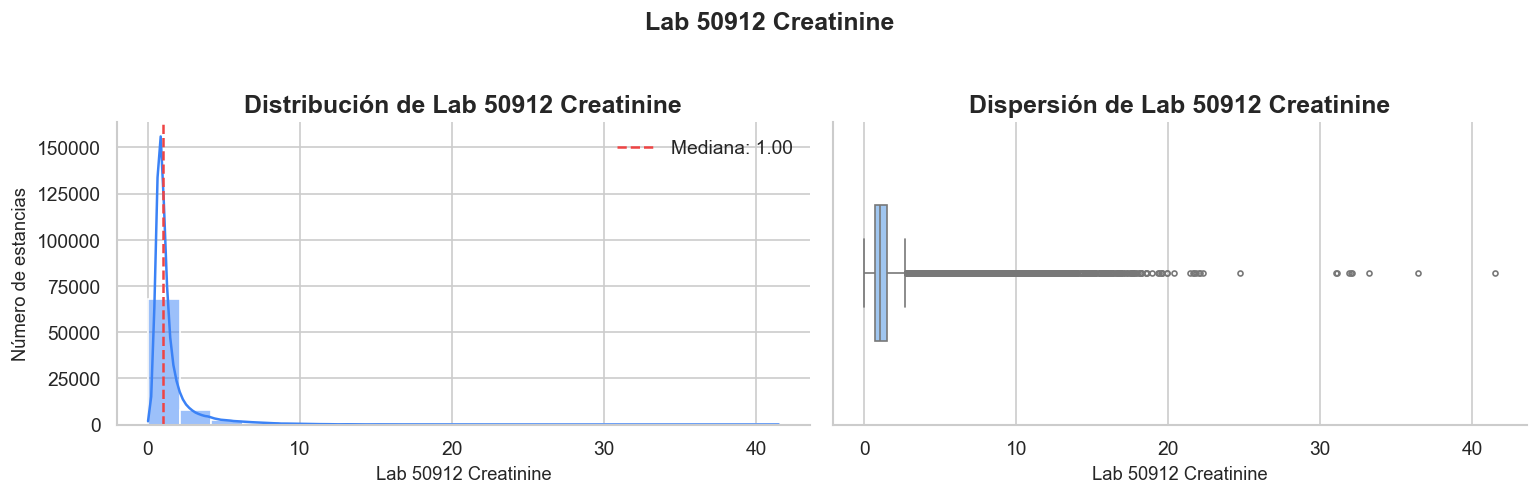

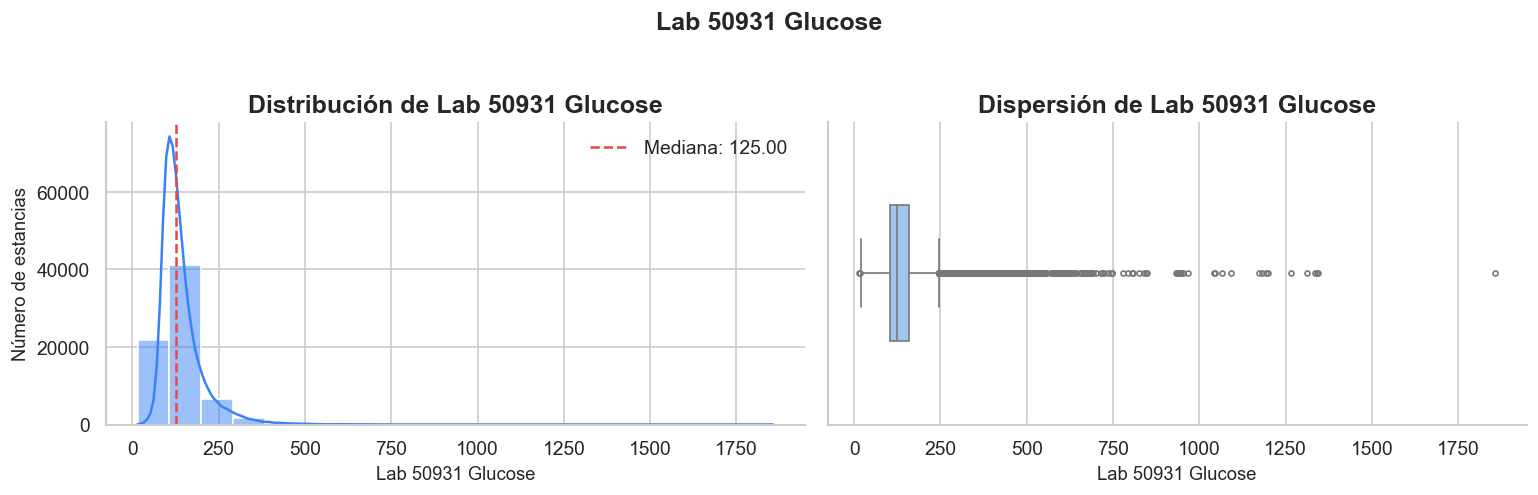

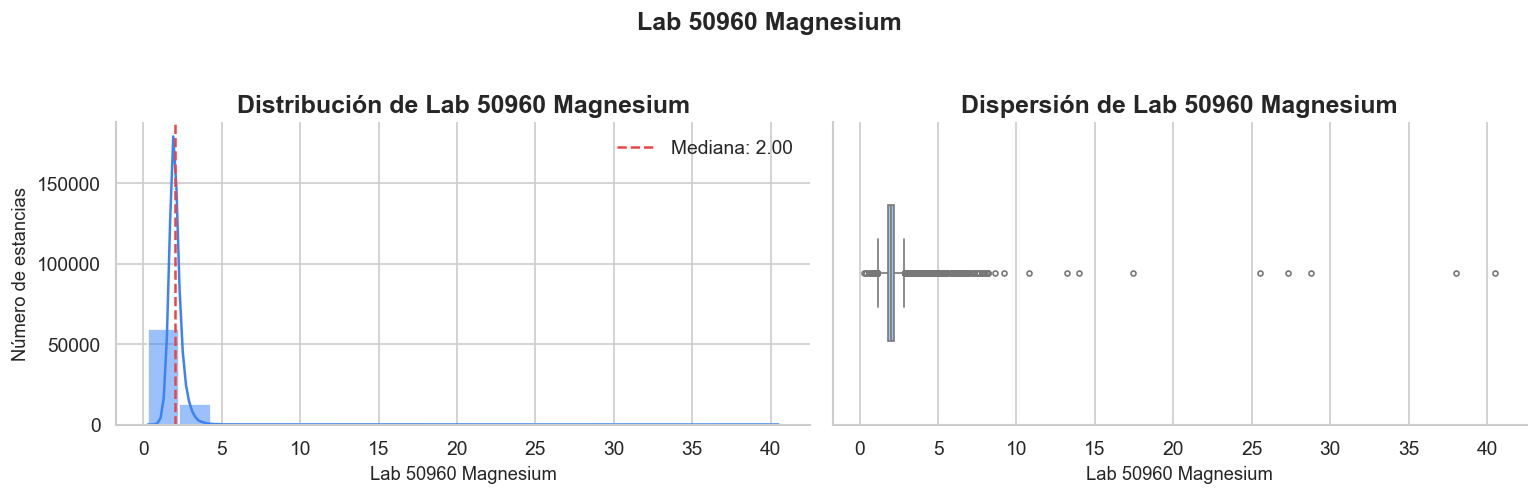

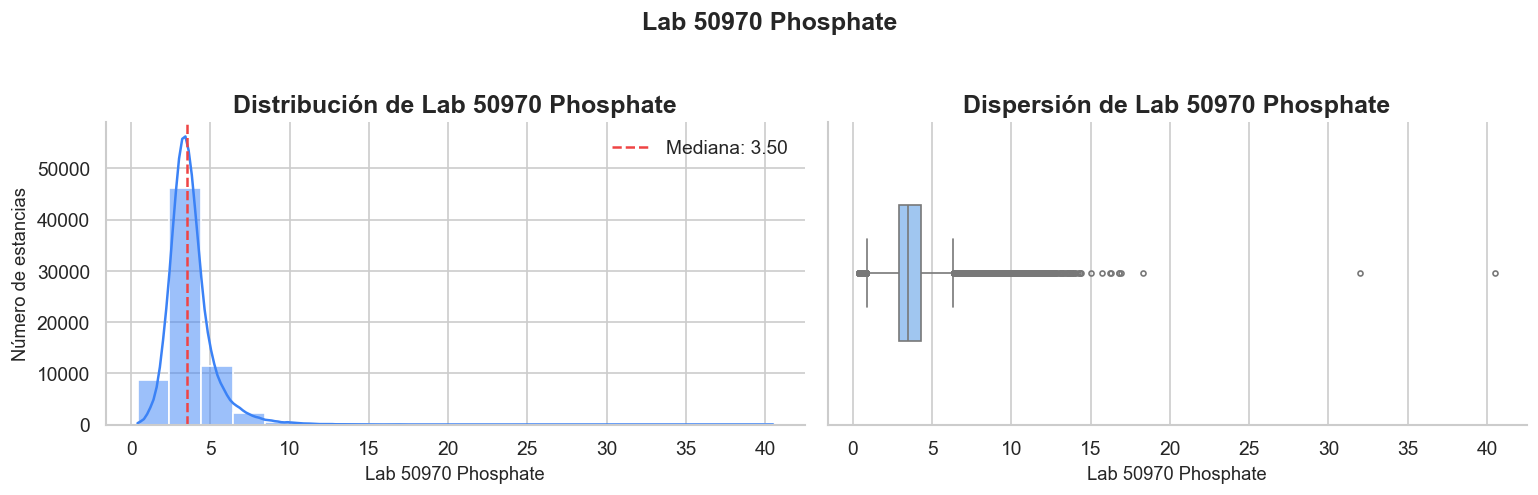

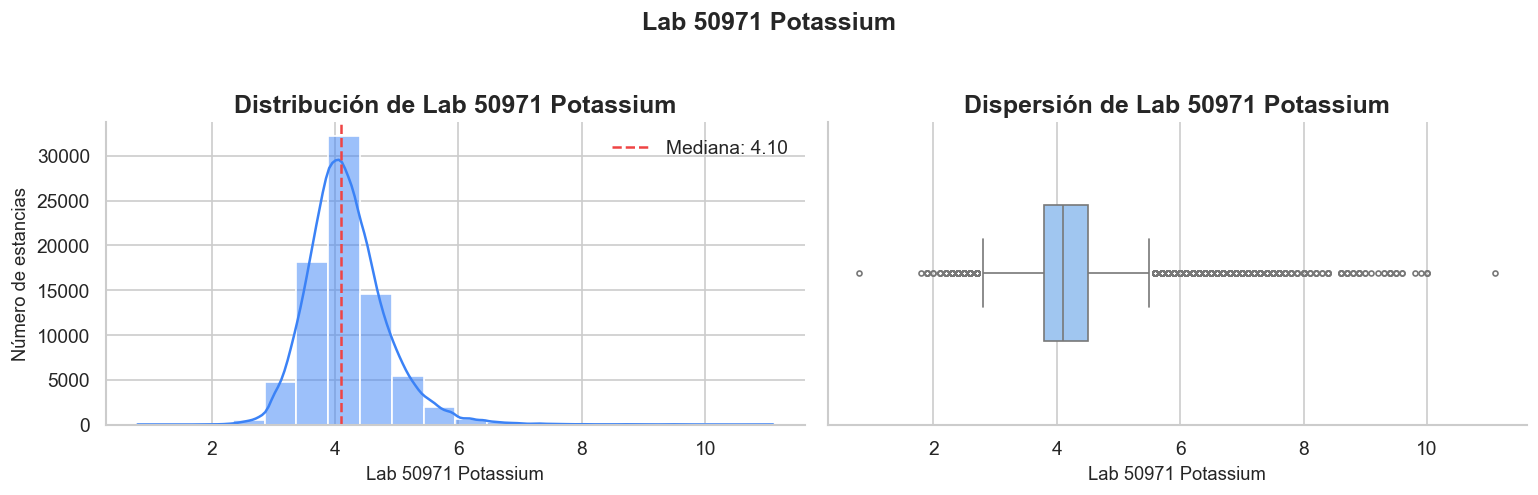

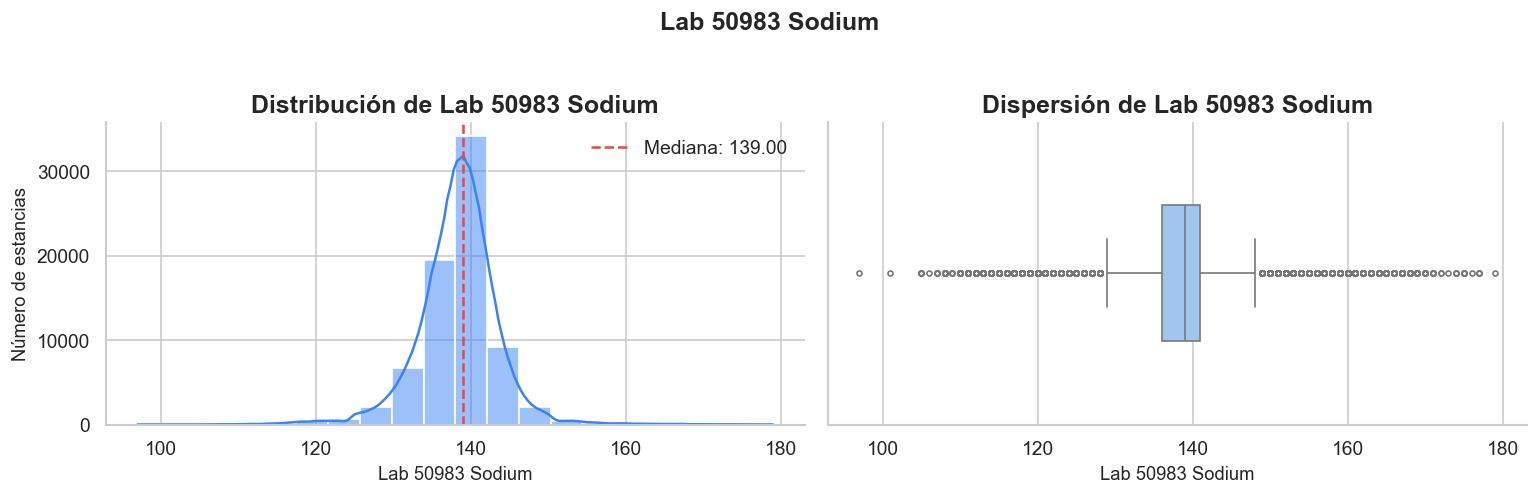

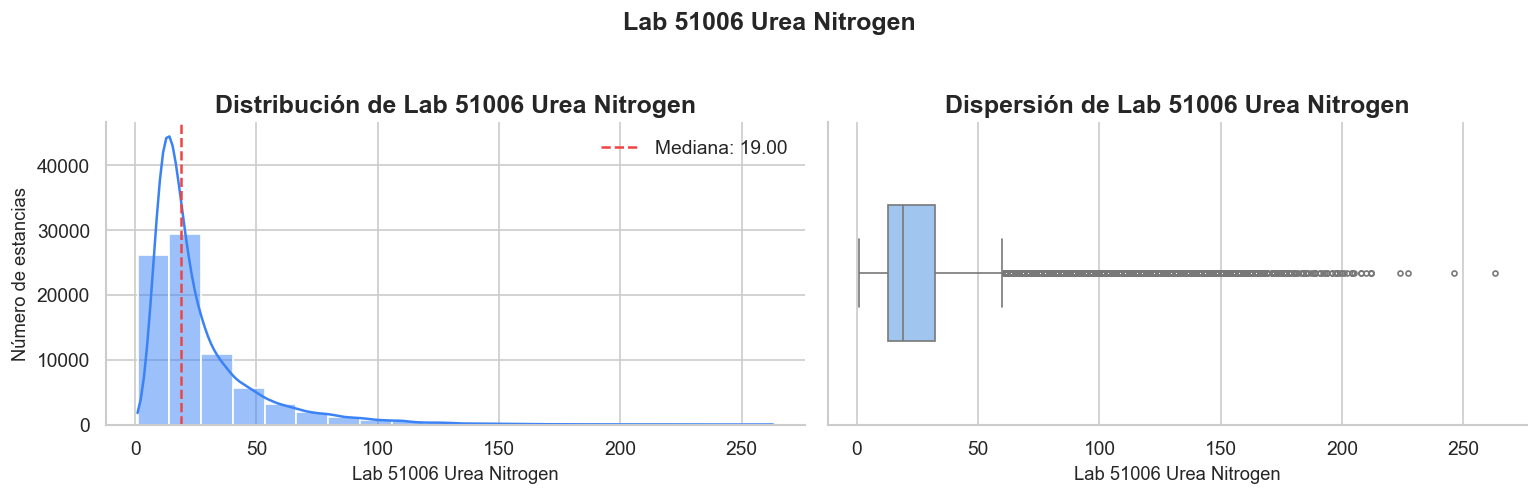

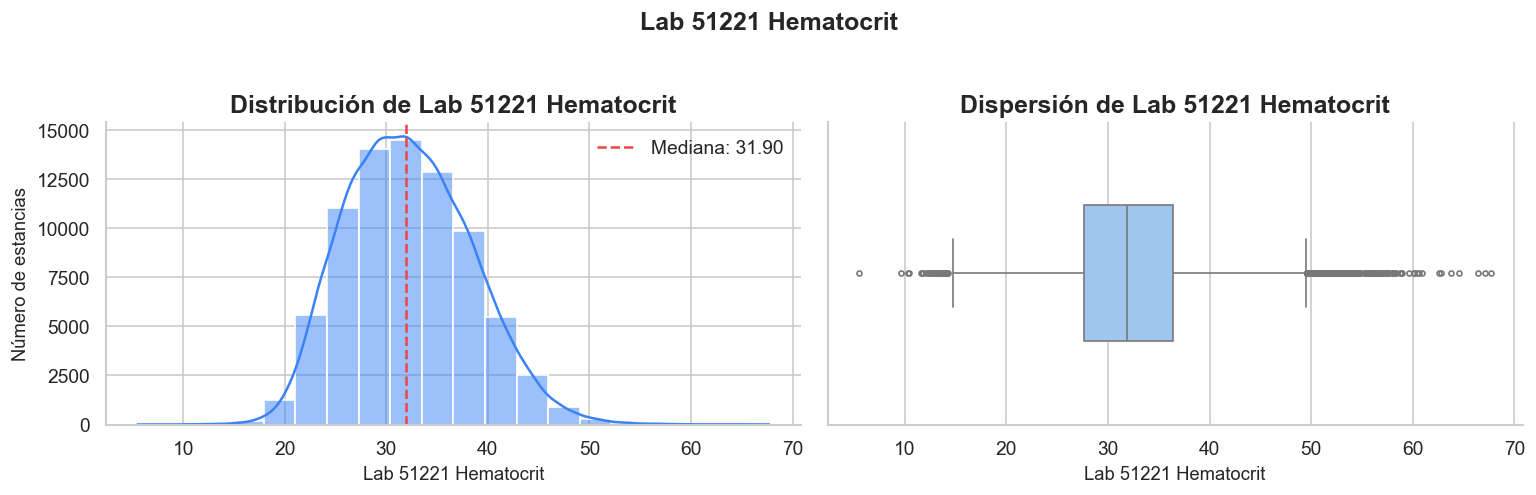

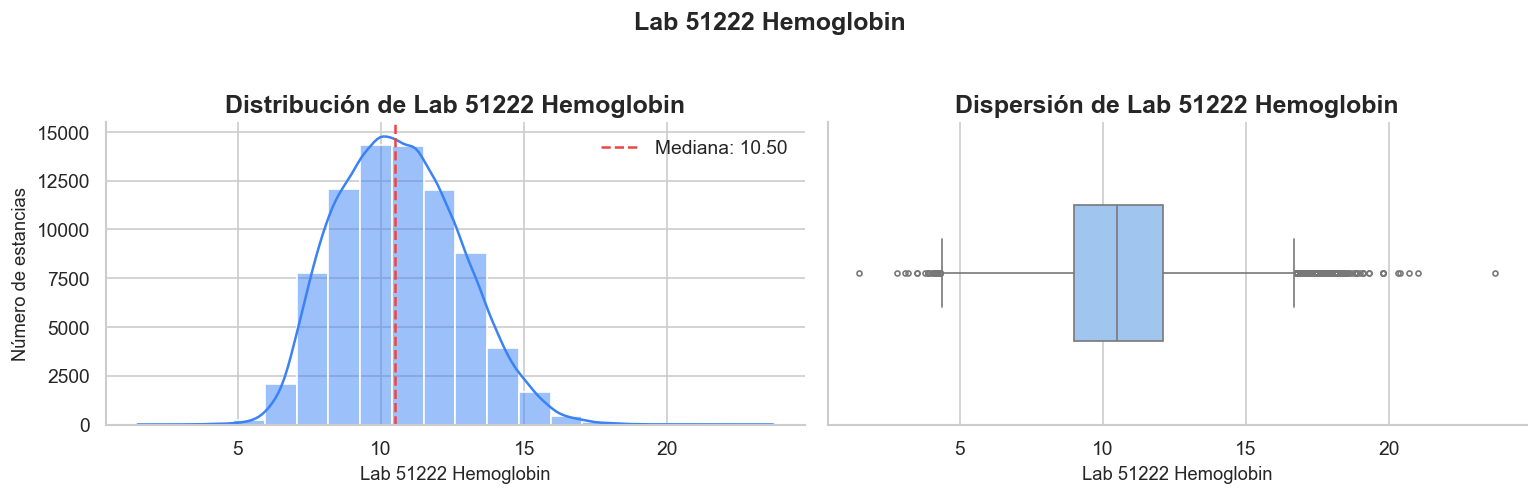

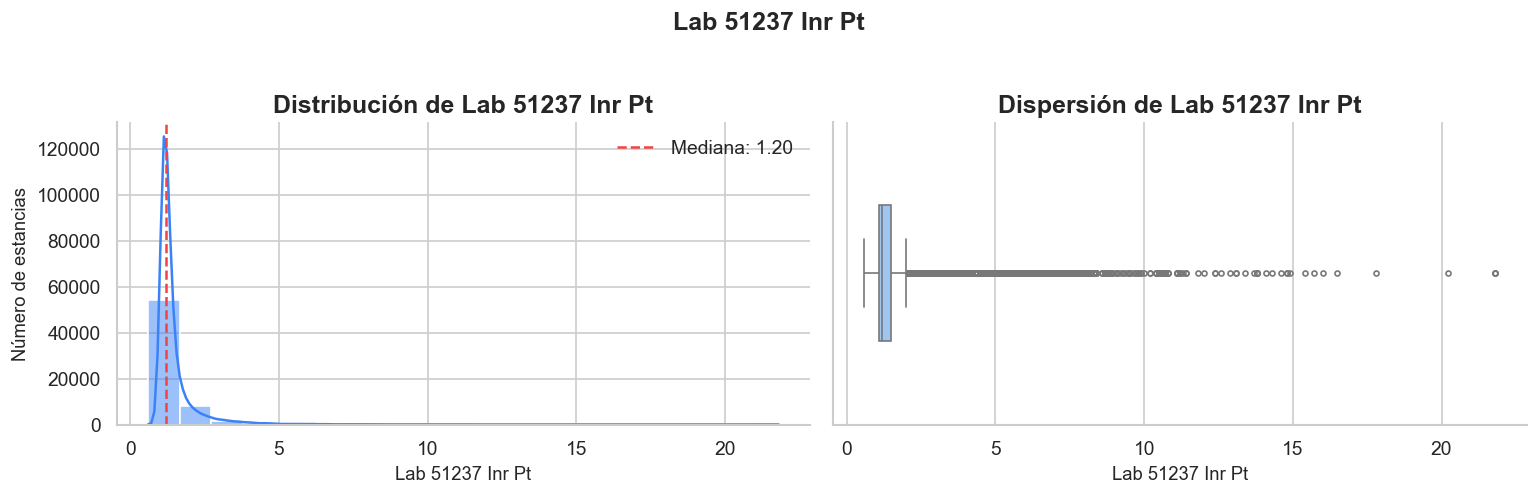

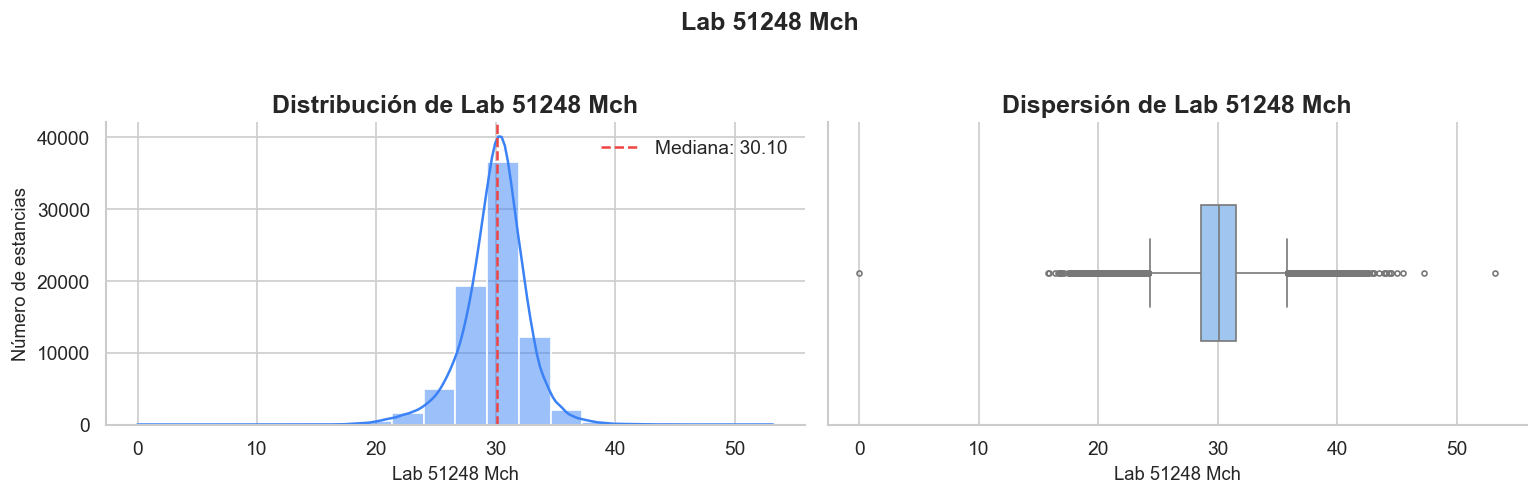

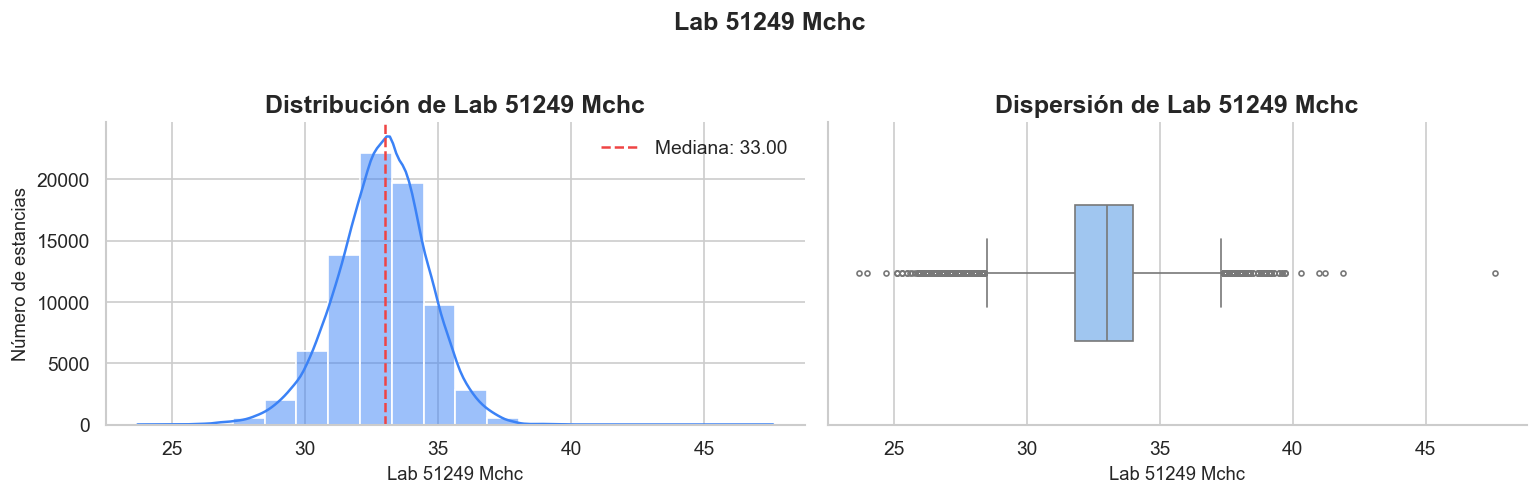

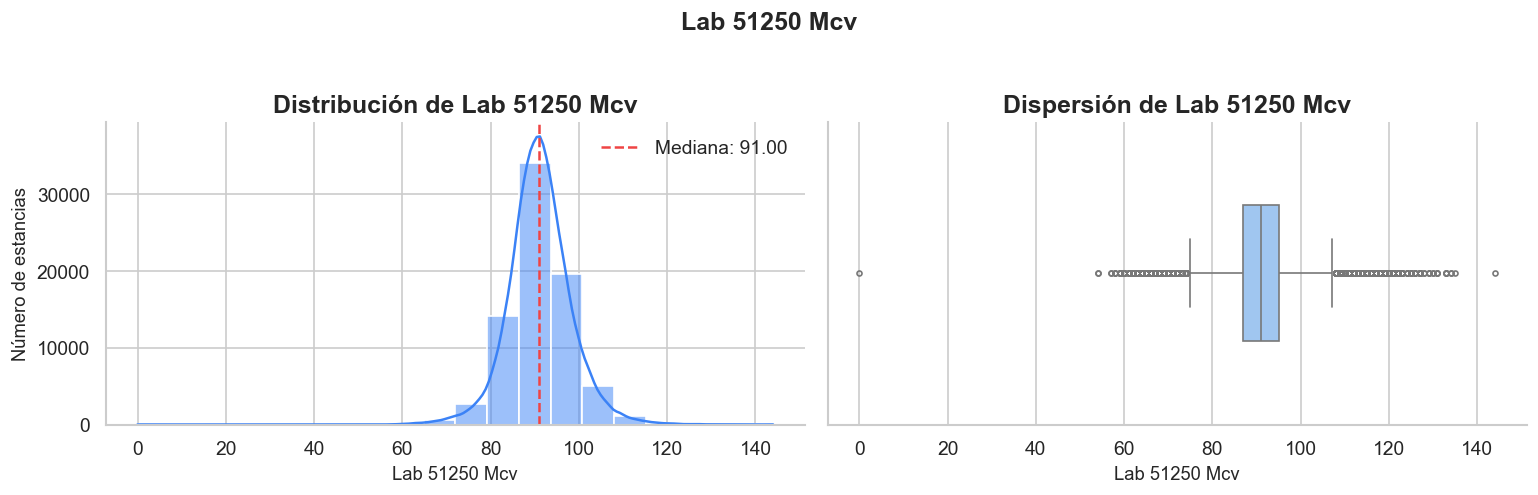

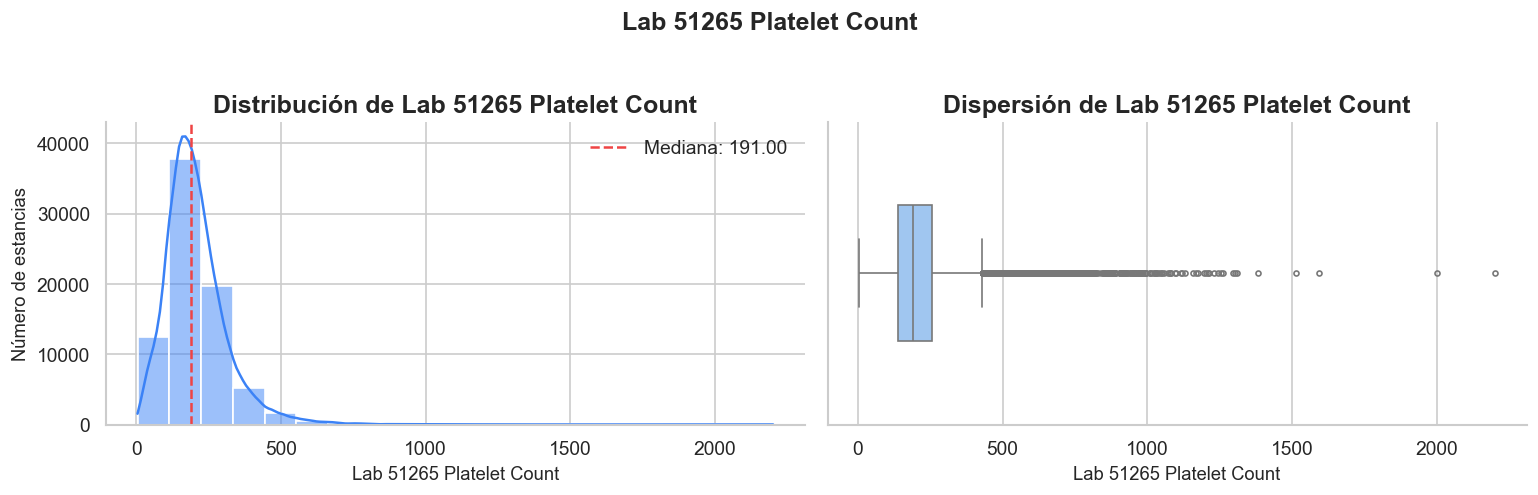

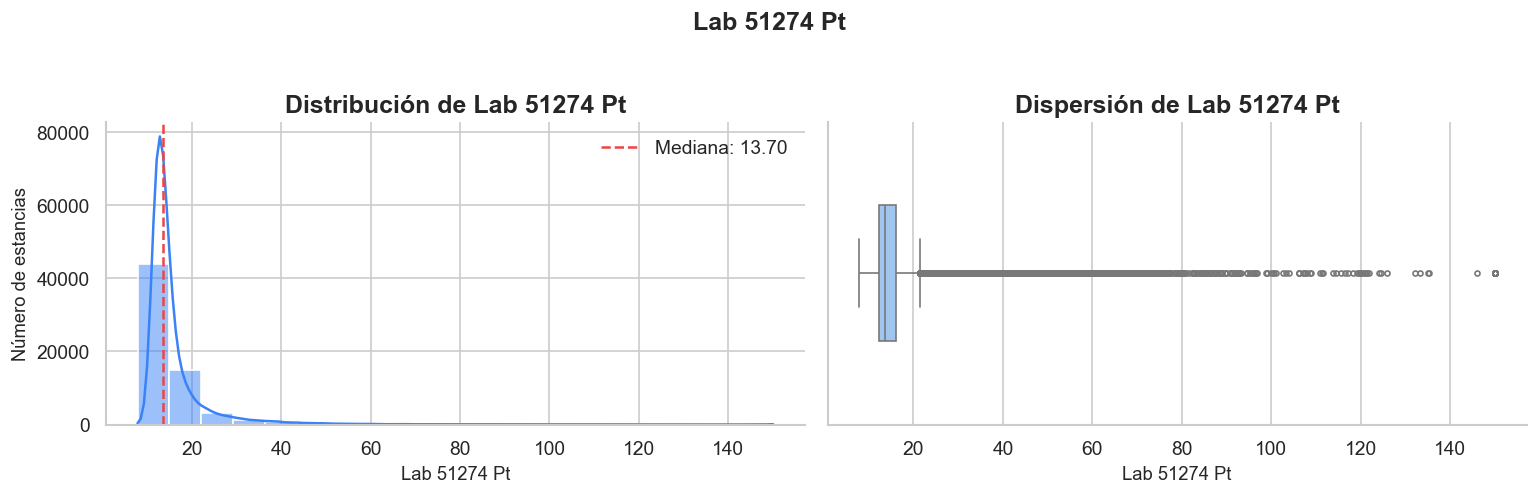

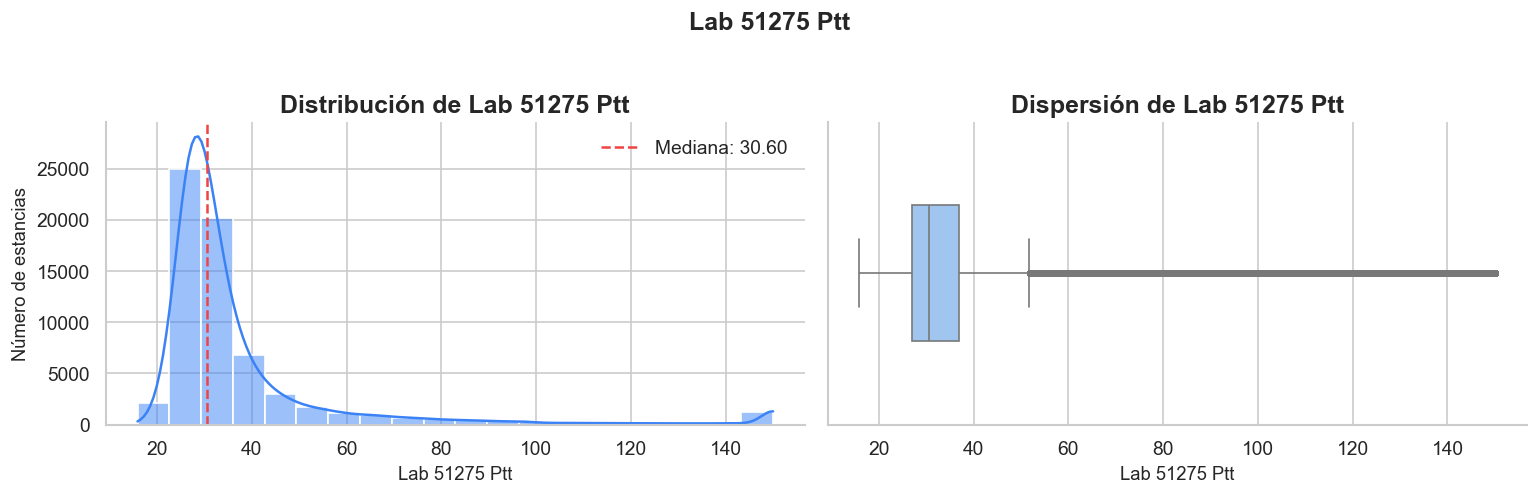

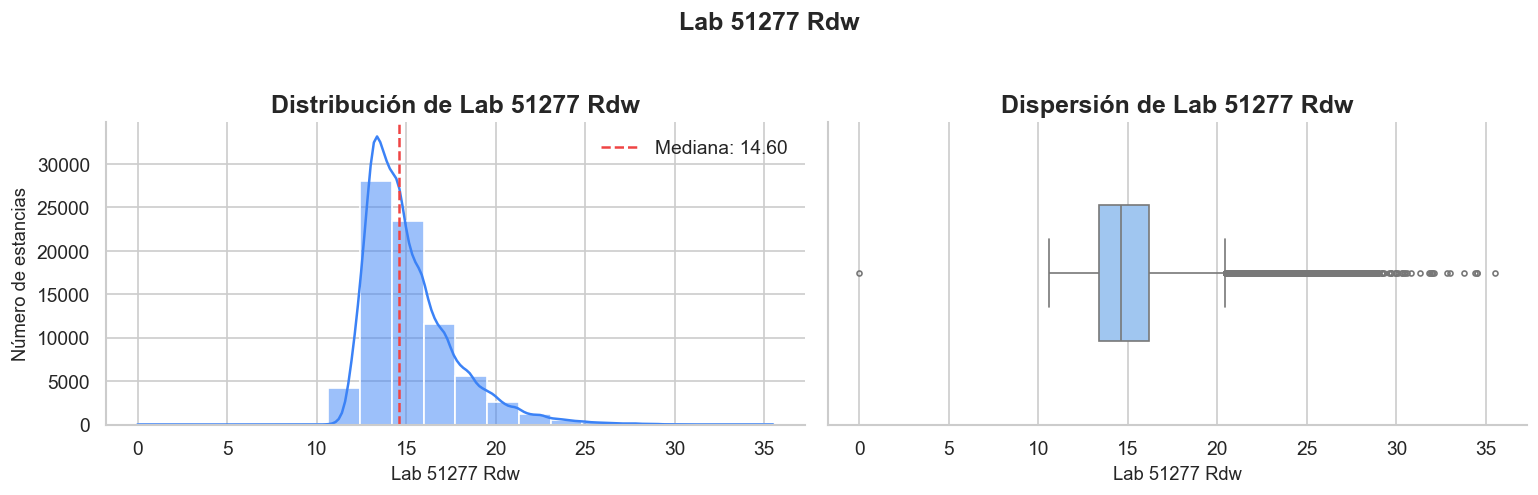

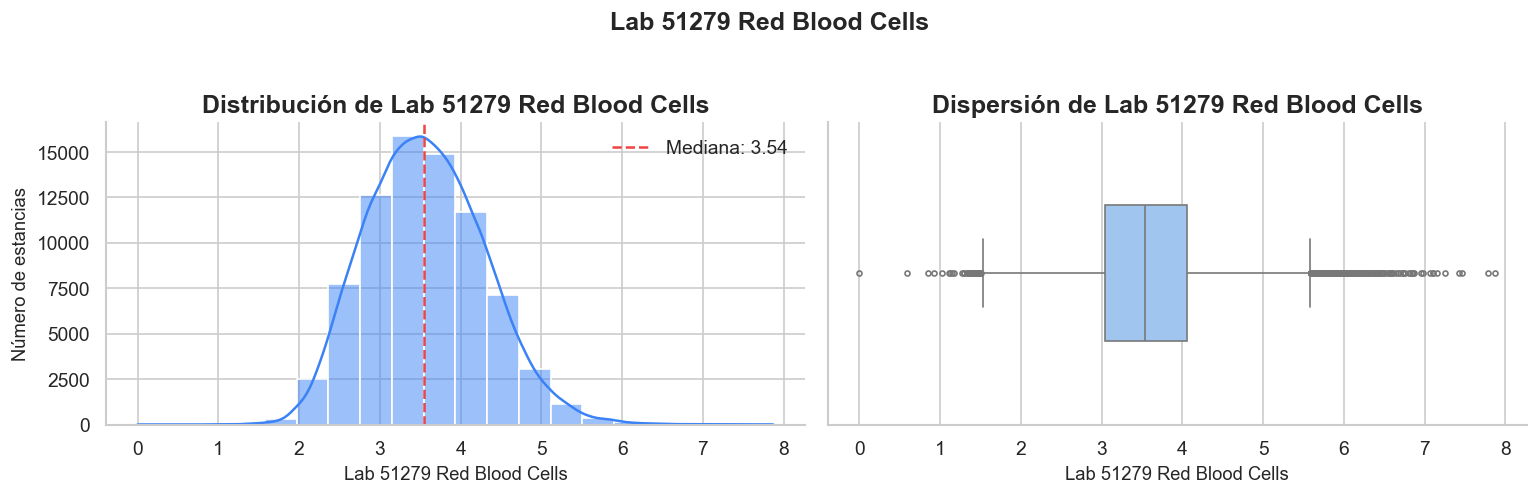

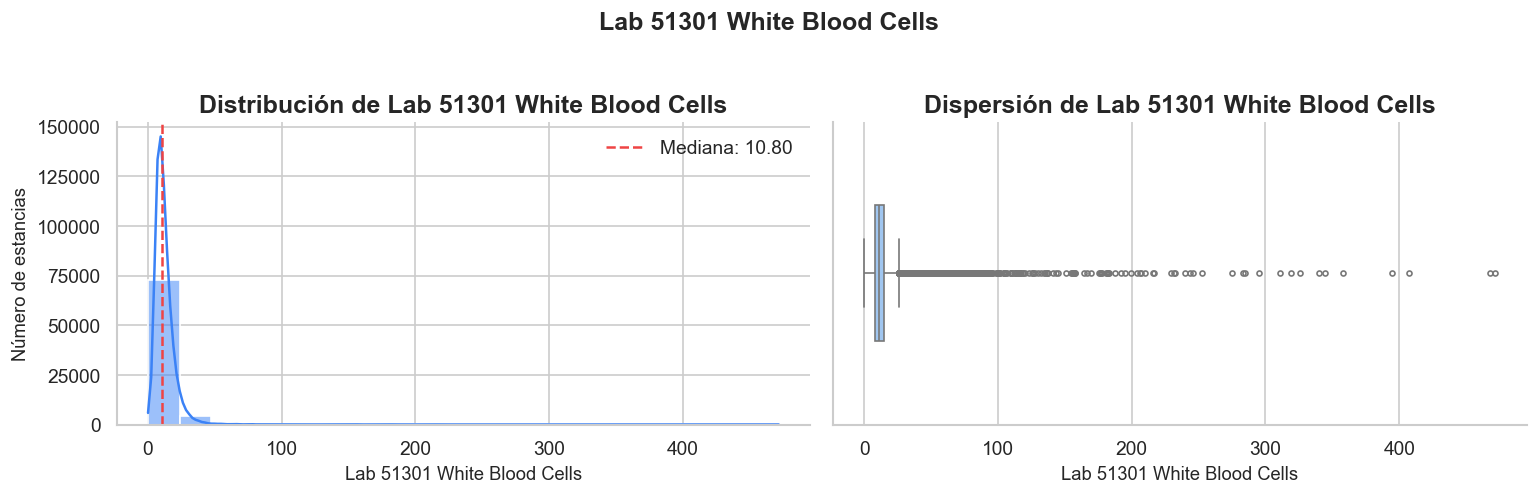

In [41]:
for variable in columnas_labs:
    if variable in dataset_analitico.columns:
        grafica_numerica(dataset_analitico, variable)

In [42]:
columnas_excluir = [
    "subject_id",
    "hadm_id",
    "stay_id",
    "los",
    "los_restante_dias"
]

# Variables numéricas disponibles en el dataset analítico
variables_numericas = [
    col
    for col in dataset_analitico.select_dtypes(include=np.number).columns
    if col not in columnas_excluir
]

resultados_spearman = []

for variable in variables_numericas:

    datos = dataset_analitico[
        [variable, "los_restante_dias"]
    ].dropna()

    # Evitar correlaciones con muy pocas observaciones
    if len(datos) < 3:
        continue

    rho, p_value = spearmanr(
        datos[variable],
        datos["los_restante_dias"]
    )

    resultados_spearman.append({
        "variable": variable,
        "rho_spearman": rho,
        "abs_rho": abs(rho),
        "p_value": p_value,
        "n": len(datos)
    })

resultados_spearman = (
    pd.DataFrame(resultados_spearman)
    .sort_values("abs_rho", ascending=False)
    .reset_index(drop=True)
)

resultados_spearman.head(15)

,variable,rho_spearman,abs_rho,p_value,n
0,lab_51006_urea_nitrogen,0.132383,0.132383,1.241903e-309,80026
1,fr_mean,0.128098,0.128098,0.000000e+00,90078
2,lab_51301_white_blood_cells,0.123540,0.123540,1.447064e-261,77615
3,temperatura_max,0.122974,0.122974,2.855738e-277,83080
4,lab_51277_rdw,0.109522,0.109522,1.821049e-205,77529
5,lab_50931_glucose,0.108151,0.108151,1.454501e-185,71739
6,lab_51237_inr_pt,0.104362,0.104362,8.061492e-157,65001
7,fc_max,0.102256,0.102256,1.510236e-208,90356
8,temperatura_mean,0.101327,0.101327,1.805324e-188,83080
9,pas_min,-0.100616,0.100616,2.195622e-168,75185


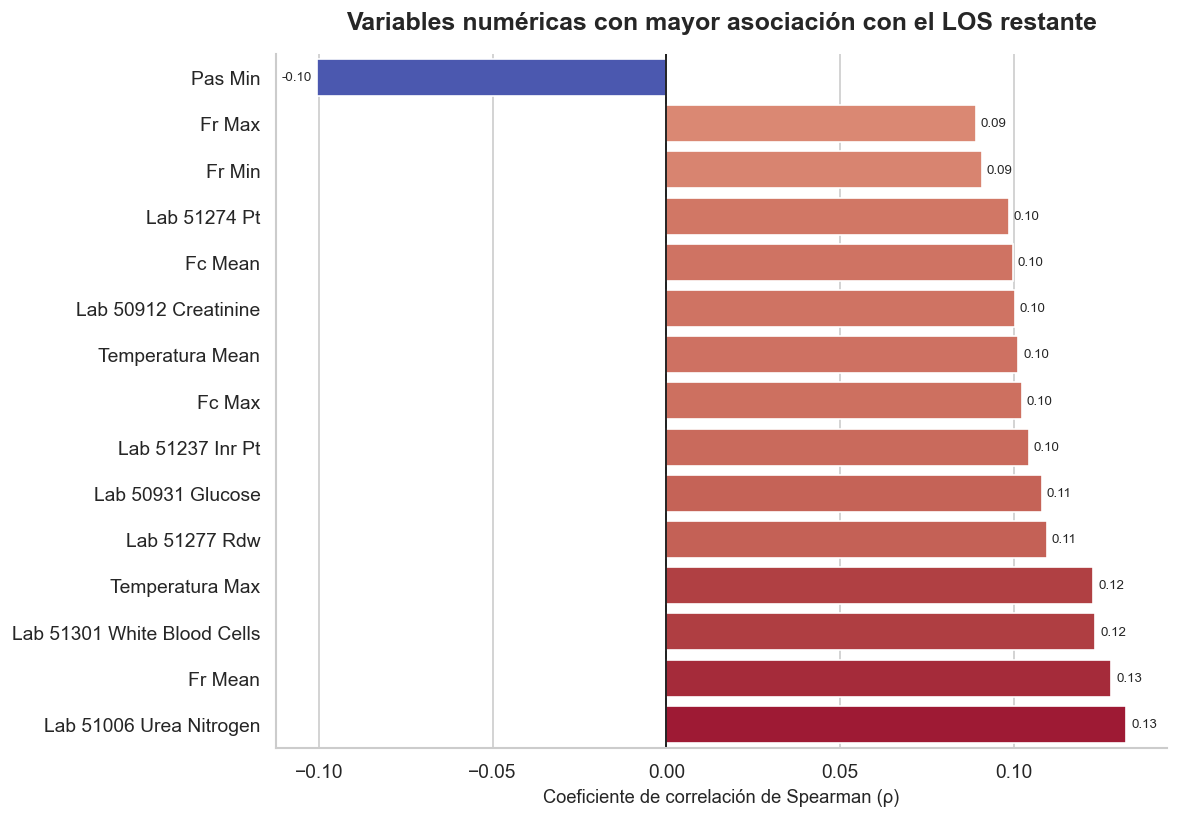

In [43]:
top_spearman = (
    resultados_spearman
    .head(15)
    .copy()
)

top_spearman["nombre"] = (
    top_spearman["variable"]
    .apply(nombre_legible)
)

top_spearman = top_spearman.sort_values(
    "rho_spearman"
)

plt.figure(figsize=(10, 7))

ax = sns.barplot(
    data=top_spearman,
    x="rho_spearman",
    y="nombre",
    hue="rho_spearman",
    palette="coolwarm",
    legend=False
)

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "Variables numéricas con mayor asociación con el LOS restante",
    pad=15
)

plt.xlabel("Coeficiente de correlación de Spearman (ρ)")
plt.ylabel("")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=8
    )

sns.despine()
plt.tight_layout()
plt.show()

# Cierre de la integración, preprocesamiento inicial y análisis exploratorio

Hasta esta etapa se realizó la **definición de la cohorte de estudio**, la integración de las distintas fuentes de información y la construcción temporalmente consistente de las variables, utilizando únicamente información disponible durante las **primeras 12 horas de estancia en UCI**. Se verificó que cada registro correspondiera a una única estancia (`stay_id`) y se construyó como variable objetivo el **tiempo restante de estancia en UCI (`los_restante_dias`)**.

Como parte del **preprocesamiento inicial y control de calidad**, se evaluó la disponibilidad de los datos y se excluyeron las variables con más del **45 % de valores faltantes**. Este criterio corresponde a disponibilidad de información y no a una selección de características basada en su capacidad predictiva. Posteriormente, se realizó el análisis exploratorio de las variables demográficas, clínicas y de laboratorio, así como de su asociación con la variable objetivo.


---


In [44]:
# ==========================================
# GUARDAR DATASET ANALÍTICO FINAL
# ==========================================

archivo_salida = INTERIM_DIR / "mimic_uci_12h_dataset_analitico.csv.gz"

dataset_analitico.to_csv(
    archivo_salida,
    index=False,
    compression="gzip"
)

print("Dataset guardado correctamente")
print("Ruta:", archivo_salida)
print("Dimensiones:", dataset_analitico.shape)


Dataset guardado correctamente
Ruta: C:\Users\grise\Downloads\estancia-hospitalaria-uci\data\interim\mimic_uci_12h_dataset_analitico.csv.gz
Dimensiones: (90467, 54)
